In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import mutual_info_classif   # for feature-target association
from matplotlib_venn import venn3                           # for visualizing intersections of missing values
from IPython.display import display                         # Jupyter Notebook for better table display
from upsetplot import from_indicators, UpSet                # for visualizing intersections of missing values
import ptitprince as pt                                     # for feature distribution visualization


import warnings                                             # to ignore future warnings
warnings.filterwarnings("ignore") #category=FutureWarning)

# ✅ Data Quality Assessment 

In [2]:
df = pd.read_csv("water_potability.csv")
Data = pd.DataFrame(df)             
display(Data.head(10))

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
5,5.584087,188.313324,28748.687739,7.544869,326.678363,280.467916,8.399735,54.917862,2.559708,0
6,10.223862,248.071735,28749.716544,7.513408,393.663396,283.651634,13.789695,84.603556,2.672989,0
7,8.635849,203.361523,13672.091764,4.563009,303.309771,474.607645,12.363817,62.798309,4.401425,0
8,NaN,118.988579,14285.583854,7.804174,268.646941,389.375566,12.706049,53.928846,3.595017,0
9,11.180284,227.231469,25484.508491,9.077200,404.041635,563.885481,17.927806,71.976601,4.370562,0


In [3]:
print(f"\nThe shape of Dataframe is : \n\n{Data.shape}")


The shape of Dataframe is : 

(3276, 10)


In [4]:
total_cells = Data.shape[0] * Data.shape[1]     # counting total number of cells in the DataFrame 
                                                # counting total number of rows and columns in the DataFrame
print(f'\nthe total number of data in Data is : {total_cells}')


the total number of data in Data is : 32760


In [5]:
print(f"\nThe feture's names of Dataframe are : \n\n{Data.columns}")


The feture's names of Dataframe are : 

Index(['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity',
       'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability'],
      dtype='object')


In [6]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [7]:
print("\nDescriptive statistics of the Dataframe are : \n")
Data.describe(include='all')


Descriptive statistics of the Dataframe are : 



,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


> ##### Max Count = 3276 ->thease features have missing_values : ph/Sulfate/Trihalomethanes 
> ##### mean  = We have very different scales. Also, due to the difference in numbers, outlier/data error, some features may have very large differences.
> ##### std = It shows how spread out the data is from the mean. Some are in tenths and some are in thousands.

>>        Scattering analysis = std/mean :
>>                ph ~ 0.22 / Hardness ~ 0.39 / Solids ~ 0.4 / Chloramines ~ 0.22 / Sulfate ~ 0.12 /
>>                Conductivity ~ 0.18 / Organic_carbon ~ 0.23 / Trihalomethanes ~ 0.24 / Turbidity ~ 0.19 / 
>>                Potability ~ 1.25 (mean ≈ 0.39/std ≈ 0.48)--(About 39% drinkable and 61% undrinkable)
>    It means that all data can be useful because we have no features that std=0
>    Very different from the rest of the features, the Solids feature.


In [8]:
print(f"\nThe number of unique values for each Feature : \n\n{Data.nunique()}")


The number of unique values for each Feature : 

ph                 2785
Hardness           3276
Solids             3276
Chloramines        3276
Sulfate            2495
Conductivity       3276
Organic_carbon     3276
Trihalomethanes    3114
Turbidity          3276
Potability            2
dtype: int64


In [9]:
print(f"\nThe number of duplicate values are : {Data.duplicated().sum()}")


The number of duplicate values are : 0


In [10]:
# Total number of missing values in the DataFrame

total_missing = Data.isnull().sum().sum()
total_cells = Data.shape[0] * Data.shape[1]

missing_percent = (total_missing / total_cells) * 100

print(f"\nTotal number of missing values in the DataFrame are :")
print(f"\nTotal Missing Values -> {total_missing}")
print(f"\nMissing Percentage -> {missing_percent:.2f}%")


Total number of missing values in the DataFrame are :

Total Missing Values -> 1434

Missing Percentage -> 4.38%


In [11]:
# Total number of missing values in each feature of the DataFrame

missing_count = Data.isnull().sum()
missing_percent = Data.isnull().mean() * 100


missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_percent.round(3)
})

fetures_missing_df = pd.DataFrame({
    "Feature": missing_table.index,
    "Missing Count": missing_table["Missing Count"].values,
    "Missing Percentage (%)": missing_table["Missing Percentage (%)"].values
})

print("\nThe count of missing_values in each feature of Dataframe are :")

fetures_missing_df


The count of missing_values in each feature of Dataframe are :


,Feature,Missing Count,Missing Percentage (%)
0,ph,491,14.988
1,Hardness,0,0.000
2,Solids,0,0.000
3,Chloramines,0,0.000
4,Sulfate,781,23.840
5,Conductivity,0,0.000
6,Organic_carbon,0,0.000
7,Trihalomethanes,162,4.945
8,Turbidity,0,0.000
9,Potability,0,0.000


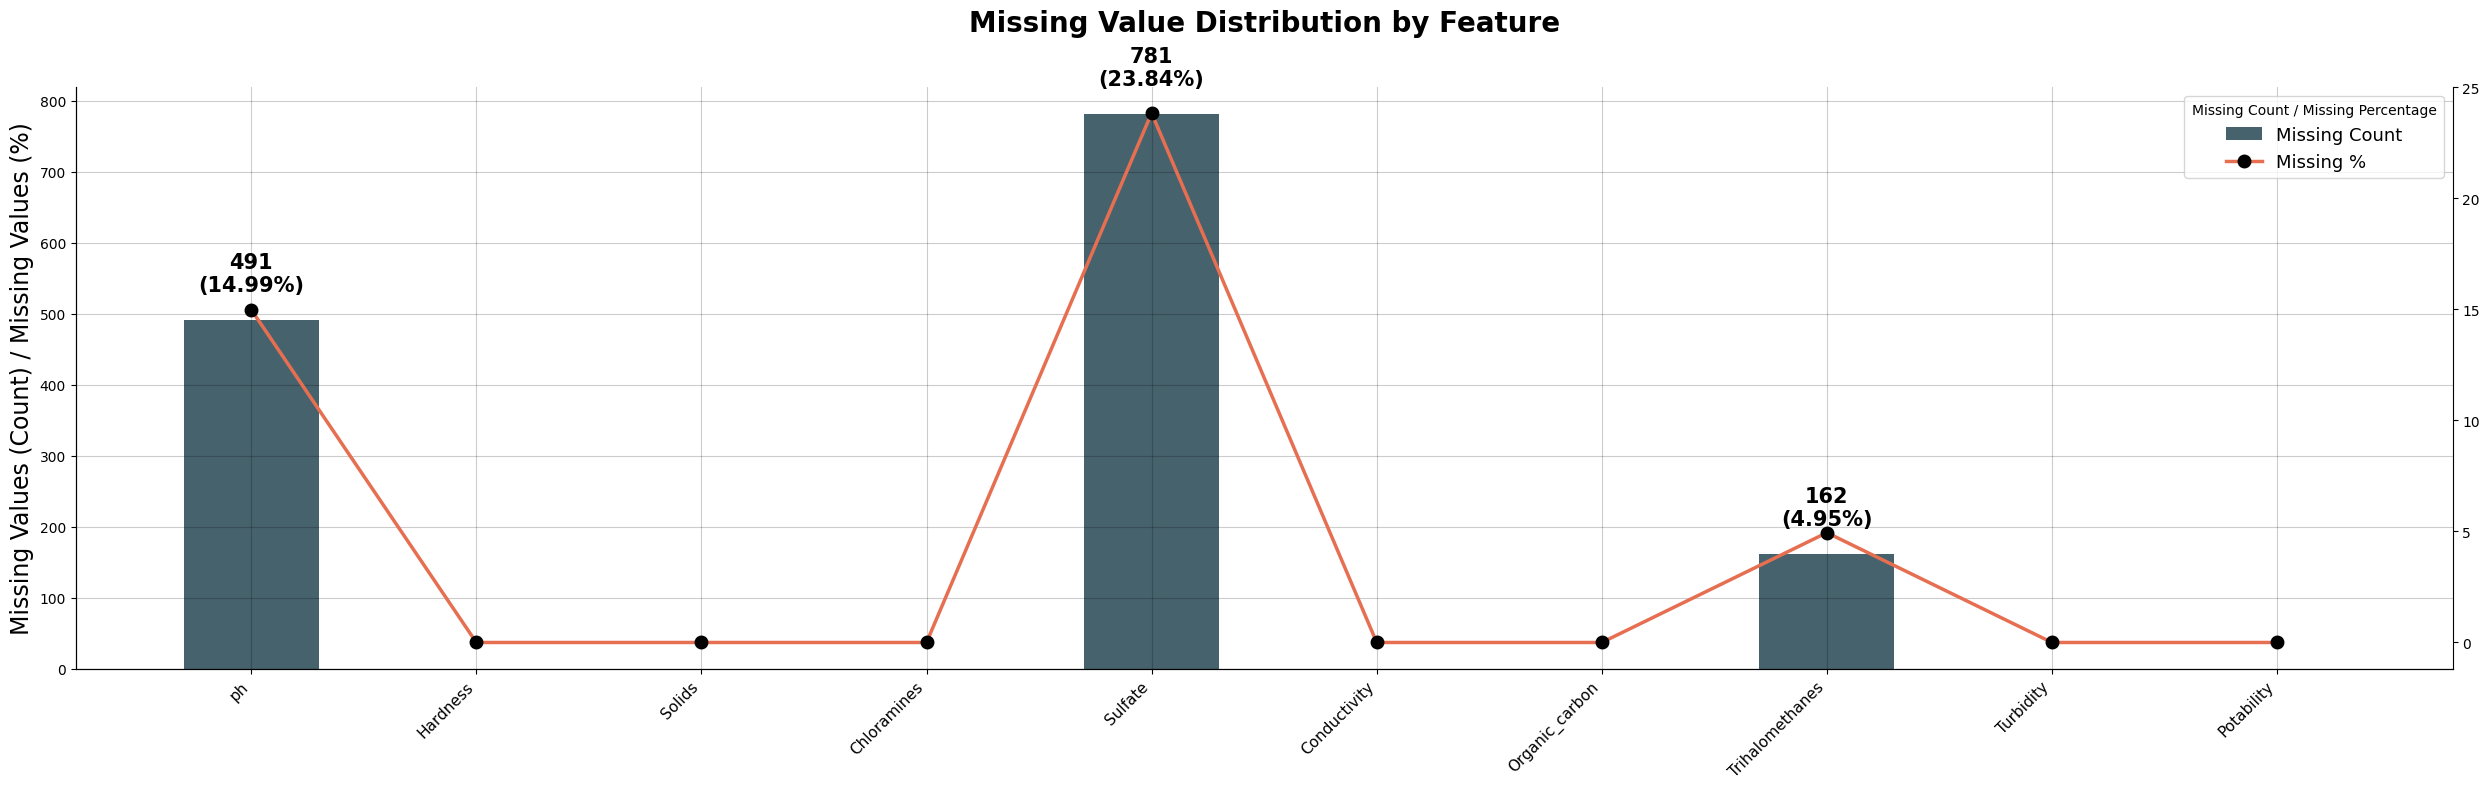

In [12]:
missing_count = Data.isnull().sum()
missing_percent = Data.isnull().mean() * 100

features = Data.columns
x = np.arange(len(features))

fig, ax1 = plt.subplots(figsize=(25, 8), facecolor="white")

# Bars
bars = ax1.bar(
    x, missing_count,
    width=0.6,
    alpha=0.85,
    color="#264653",
    label="Missing Count"
)

# Main axis
ax1.set_facecolor("white")
ax1.set_ylabel(
    "Missing Values (Count) / Missing Values (%)",
    fontsize=17,
    color="black"
)
ax1.set_xticks(x)
ax1.set_xticklabels(features, rotation=45, ha="right", fontsize=11)

# Percentage line
ax2 = ax1.twinx()

ax2.plot(
    x, missing_percent,
    color="#E76F51",
    marker="o",
    markerfacecolor="black",
    markeredgecolor="black",
    markeredgewidth=2,
    linewidth=2.5,
    markersize=8,
    label="Missing %"
)

# Labels
for bar, count, pct in zip(bars, missing_count, missing_percent):
    if count > 0:
        ax1.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 35,
            f"{count}\n({pct:.2f}%)",
            ha="center",
            va="bottom",
            fontsize=15,
            fontweight="bold",
            color="black"
        )

# Title
ax1.set_title(
    "Missing Value Distribution by Feature",
    fontsize=20,
    fontweight="bold",
    color="black",
    pad=40
)

# Spines & grid
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

ax1.grid(
    True,
    alpha=0.2,
    color="black",
    linestyle="-"
)

# Combined legend
handles = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]

ax1.legend(
    handles,
    labels,
    title="Missing Count / Missing Percentage",
    loc="upper right",
    frameon=True,
    fontsize=13
)

plt.tight_layout()
plt.show()

> #### Since there is missing data in only 3 features, we can examine only those 3 features and show the rows that have at least one missing value.

In [13]:
cols_with_nan = ['ph', 'Sulfate', 'Trihalomethanes']

print("\nThe rows with missing values in the Dataframe are : \n")

Data[Data[cols_with_nan].isnull().any(axis=1)][cols_with_nan]


The rows with missing values in the Dataframe are : 



,ph,Sulfate,Trihalomethanes
0,NaN,368.516441,86.990970
1,3.716080,NaN,56.329076
2,8.099124,NaN,66.420093
8,NaN,268.646941,53.928846
11,7.974522,NaN,76.485911
...,...,...,...
3266,8.372910,NaN,38.435151
3272,7.808856,NaN,NaN
3273,9.419510,NaN,69.845400
3274,5.126763,NaN,77.488213


In [14]:
# I calculated the percentage of rows that have 0, 1, 2 or 3 missing values

row_missing = Data[cols_with_nan].isnull().sum(axis=1)   # I created a series to check the number, but I didn't create a column

row_missing_count = row_missing.value_counts().sort_index()

row_missing_percent = (
    row_missing_count / len(Data) * 100
).round(2)

row_missing_df = pd.DataFrame({
    'Missing_per_row': row_missing_count.index,
    'Count': row_missing_count.values,
    'Percent': row_missing_percent.values
})

print("\nThe count/percentage of missing_values in each row of Dataframe are :")

row_missing_df


The count/percentage of missing_values in each row of Dataframe are :


,Missing_per_row,Count,Percent
0,0,2011,61.39
1,1,1105,33.73
2,2,151,4.61
3,3,9,0.27


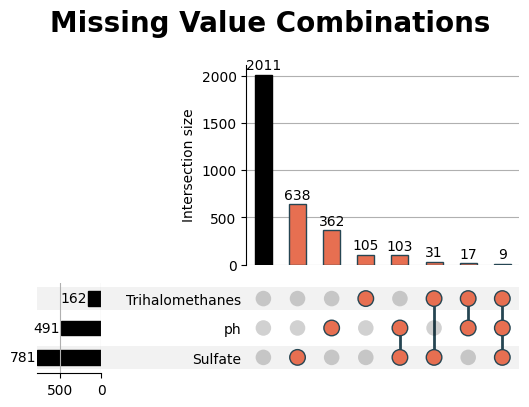

In [15]:
cols_with_nan = ["ph", "Sulfate", "Trihalomethanes"]

upset_data = from_indicators(
    Data[cols_with_nan].isnull(),
    data=Data
)

fig = plt.figure(figsize=(25, 6))

upset = UpSet(
    upset_data,
    show_counts=True,
    sort_by="cardinality"
)

for col in cols_with_nan:
    upset.style_subsets(
        present=col,
        facecolor="#E76F51",
        edgecolor="#264653"
    )

upset.plot(fig=fig)

fig.suptitle(
    "Missing Value Combinations",
    fontsize=20,
    fontweight="bold",
    color="black",
    y=1.02
)

plt.tight_layout()
plt.show()

> ##### In the output, we see what pattern it follows in one-by-one, two-by-two, and three-by-three for the missing_values in our features base on rows

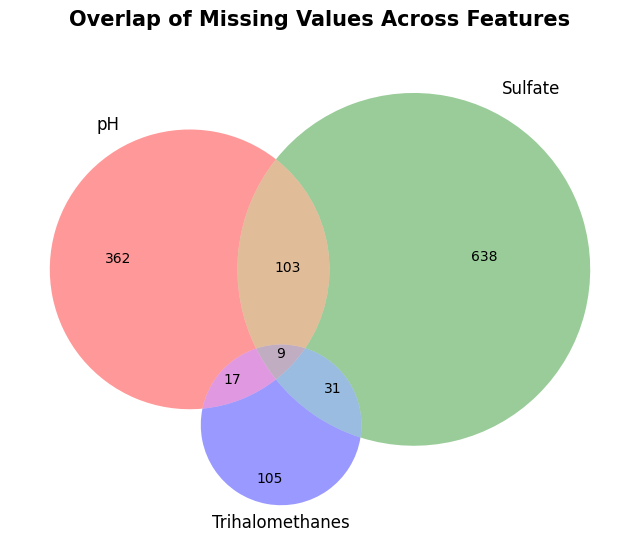

In [16]:
ph = Data["ph"].isnull()
sulfate = Data["Sulfate"].isnull()
thm = Data["Trihalomethanes"].isnull()

#  ph
only_ph = (ph & ~sulfate & ~thm).sum()

#  Sulfate
only_sulfate = (~ph & sulfate & ~thm).sum()

#  THM
only_thm = (~ph & ~sulfate & thm).sum()

# ph و Sulfate
ph_sulfate = (ph & sulfate & ~thm).sum()

# ph و THM
ph_thm = (ph & ~sulfate & thm).sum()

# Sulfate و THM
sulfate_thm = (~ph & sulfate & thm).sum()

# ph و Sulfate و THM
all_three = (ph & sulfate & thm).sum()


plt.figure(figsize=(8,8))

venn3(
    subsets=(
        only_ph,
        only_sulfate,
        ph_sulfate,
        only_thm,
        ph_thm,
        sulfate_thm,
        all_three
    ),
    set_labels=("pH", "Sulfate", "Trihalomethanes")
)

plt.title(
    "Overlap of Missing Values Across Features", 
    loc="center", 
    pad=20, 
    fontsize=15,
    fontweight="bold")



plt.show()



> ##### Here is another view of the missing_values that also shares rows in these three features.

-------

# ✅ Missing_value Handling 

> #### So far we have found that we do not have duplicate data
> #### Which columns can contain outlier data
> #### Where are the missing values?

In [17]:
# Before anything else, it's best to have a copy of your data so that if something goes wrong, you can revert to the original data.

Data_Clean = Data.copy()

In [18]:
# I removed the samples that have 3 missing values, because these rows are very few and removing them does not cause any problems.

row_missing = Data_Clean[cols_with_nan].isnull().sum(axis=1)

rows_to_keep = row_missing != 3

Data_Clean = Data_Clean[rows_to_keep]

In [19]:
# I checked to see if rows with 3 missing values ​​were removed and displayed the number of rows with 0, 1, or 2 missing values

row_missing = Data_Clean[cols_with_nan].isnull().sum(axis=1)

row_missing_count = row_missing.value_counts().sort_index()

row_missing_percent = (
    row_missing_count / len(Data_Clean) * 100
).round(2)

row_missing_df = pd.DataFrame({
    'Missing_per_row': row_missing_count.index,
    'Count': row_missing_count.values,
    'Percent': row_missing_percent.values
})

print("\nThe count/percentage of missing_values in each row of Dataframe after removing rows with 3 missing values are :")

row_missing_df


The count/percentage of missing_values in each row of Dataframe after removing rows with 3 missing values are :


,Missing_per_row,Count,Percent
0,0,2011,61.55
1,1,1105,33.82
2,2,151,4.62


In [20]:
# This code shows all the columns that have at least one missing value and displays the first 20 rows of it.

missing_values_columns = df[Data_Clean.columns[Data.isnull().any()].tolist()]

print("\nThe columns with missing values after removing rows with 3 missing values in the Dataframe are : \n")

missing_values_columns.head(20)


The columns with missing values after removing rows with 3 missing values in the Dataframe are : 



,ph,Sulfate,Trihalomethanes
0,NaN,368.516441,86.990970
1,3.716080,NaN,56.329076
2,8.099124,NaN,66.420093
3,8.316766,356.886136,100.341674
4,9.092223,310.135738,31.997993
5,5.584087,326.678363,54.917862
6,10.223862,393.663396,84.603556
7,8.635849,303.309771,62.798309
8,NaN,268.646941,53.928846
9,11.180284,404.041635,71.976601


In [21]:
# Here I want to check the correlation between columns that have missing data and see if we can use one column to fill in the missing data in another column.

print("\nThe correlation between columns that have missing data are : \n")

Data_Clean[cols_with_nan].corr()


The correlation between columns that have missing data are : 



,ph,Sulfate,Trihalomethanes
ph,1.000000,0.018203,0.003354
Sulfate,0.018203,1.000000,-0.030274
Trihalomethanes,0.003354,-0.030274,1.000000


> ##### As is clear, the correlation between these three columns is close to zero, but we can still check the situation with the other columns to see what happens.
>> - |r| < 0.3 → Weak correlation
>> - 0.3 < |r| < 0.7 → Normal correlation
>> - |r| > 0.7 → Strong correlation

In [22]:
corr = Data_Clean.corr()

print("\nThe correlation between columns that have missing data with other features are : \n")

corr[['ph', 'Sulfate', 'Trihalomethanes']]


The correlation between columns that have missing data with other features are : 



,ph,Sulfate,Trihalomethanes
ph,1.000000,0.018203,0.003354
Hardness,0.082096,-0.106923,-0.013013
Solids,-0.089288,-0.171804,-0.009143
Chloramines,-0.034350,0.027244,0.017084
Sulfate,0.018203,1.000000,-0.030274
Conductivity,0.018614,-0.016121,0.001285
Organic_carbon,0.043503,0.030831,-0.013274
Trihalomethanes,0.003354,-0.030274,1.000000
Turbidity,-0.039057,-0.011187,-0.022145
Potability,-0.003556,-0.023577,0.007130


> - The features are correlated with NONE of these 3 features.
> - The largest coefficient is around -0.17, which is still considered weak.
> ##### As a result: There is no significant correlation between Feature

In [23]:
# Here I also checked the distribution between these three columns to see if we can use one column to fill in missing data in another column.

print("\nThe skewness of columns that have missing data are : \n")

Data_Clean[['ph', 'Sulfate', 'Trihalomethanes']].skew()


The skewness of columns that have missing data are : 



ph                 0.025630
Sulfate           -0.035947
Trihalomethanes   -0.083031
dtype: float64

> - Skewness ≈ 0 → Approximately normal and symmetrical distribution.
> - Skewness > 0 → The distribution sequence is right-skewed.
> - Skewness < 0 → The distribution sequence is left-skewed.
> Conclusion
> - Between -0.5 and 0.5 → Almost symmetrical
> - Between 0.5 and 1 or -0.5 and -1 → Moderate skewness
> - More than 1 or less than -1 → Severe skewness
> ##### We actually notice the presence of outlier data here.

## Handling missing data using KNN_algorithm

In [24]:
def simple_knn_impute(Data_Clean, target_col, k=10, debug=True ,debug_samples=2):

    feature_cols = [
        col for col in Data_Clean.columns # all of columns
        if col != target_col and Data_Clean[col].isna().sum() == 0 # target and other missing values should be ingnore
    ]

    shown = 0 # For shown some rows 

    known = Data_Clean[Data_Clean[target_col].notna()] 
    missing = Data_Clean[Data_Clean[target_col].isna()] 

    for idx, row in missing.iterrows(): # idx = index | row = the row
        
        diffs = known[feature_cols].sub(row[feature_cols]).abs()

        distances = diffs.sum(axis=1) # Manhattan distance (L1)

        nearest_idx = distances.nsmallest(k).index # k nearest neighbors (KNN)

        imputed_value = known.loc[nearest_idx, target_col].mean() # Mean of knn

        Data_Clean.at[idx, target_col] = imputed_value # The null value = now has a value

        if debug and shown < debug_samples:
            print(f"Missing sample index: {idx}")
            print("Missing row:")
            display(Data_Clean.loc[[idx]])

            print("Nearest neighbors:")
            display(Data_Clean.loc[nearest_idx])

            print(f"Imputed value for '{target_col}': {imputed_value:.4f}")
            print("Nearest neighbors indices:")
            print(list(nearest_idx))

            print("\nNeighbor values:")
            print(known.loc[nearest_idx, target_col].values)

            shown += 1

    return Data_Clean


In [25]:
Data1_Clean_After_KNN = simple_knn_impute(Data_Clean, 'Sulfate', k=10, debug_samples=2)

Missing sample index: 1
Missing row:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
1,3.71608,129.422921,18630.057858,6.635246,341.794864,592.885359,15.180013,56.329076,4.500656,0


Nearest neighbors:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
2992,NaN,196.083556,18592.083920,7.245436,321.814033,552.879034,15.664786,81.080826,4.762872,0
685,3.994498,179.454192,18682.277139,6.464793,331.145621,538.174959,13.916820,NaN,3.379147,1
2314,5.161879,179.636409,18666.563638,5.196133,400.896023,485.311954,14.059708,75.822050,4.320101,1
1347,6.265637,159.290190,18711.064662,6.835968,314.223053,499.604629,15.061714,68.107216,3.266029,0
1513,6.353437,218.549363,18664.844297,6.690394,312.393019,503.414897,15.422459,94.386932,3.861109,1
1562,NaN,190.567521,18589.031160,7.470353,362.146977,471.444769,13.760231,90.306310,4.400203,1
331,NaN,163.224466,18570.285339,8.109346,296.190262,463.741716,16.900148,61.349832,4.135745,1
2154,NaN,209.953278,18668.363826,4.453252,347.581603,479.561362,16.092975,68.799179,3.772078,0
2514,6.528479,176.939676,18533.337828,6.083268,336.296413,491.477924,13.531264,96.944104,4.063276,0
1139,6.284386,222.688795,18526.261691,8.980271,395.261637,517.150548,15.869010,55.384333,5.030712,1


Imputed value for 'Sulfate': 341.7949
Nearest neighbors indices:
[2992, 685, 2314, 1347, 1513, 1562, 331, 2154, 2514, 1139]

Neighbor values:
[321.8140325  331.14562114 400.89602333 314.2230526  312.39301924
 362.14697732 296.19026162 347.58160322 336.29641311 395.26163712]
Missing sample index: 2
Missing row:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
2,8.099124,224.236259,19909.541732,9.275884,337.839297,418.606213,16.868637,66.420093,3.055934,0


Nearest neighbors:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
989,5.392058,198.017165,19900.407838,7.843226,348.951924,419.813956,14.616509,80.568252,2.978925,0
3013,NaN,215.431919,19909.938849,6.902628,299.086418,371.482911,10.766349,85.267182,4.592538,0
755,9.888941,220.638823,19892.388914,7.986456,326.076560,460.812425,14.929172,59.602808,3.750164,1
3214,5.500277,263.683160,19911.224900,4.755312,366.942743,435.865696,12.761184,51.439894,5.147536,1
2104,NaN,165.740229,19919.324589,7.278151,351.965054,420.120713,17.776053,46.002340,3.428096,0
653,5.970579,202.745520,19952.309470,7.872038,311.188185,412.038922,18.632142,73.166338,5.013281,0
3109,6.283679,205.376624,19905.436548,7.078345,284.206021,471.904032,18.027160,64.362608,4.480771,0
1960,8.128270,231.167537,19954.575554,5.138838,349.067363,386.071149,15.018085,63.340968,4.678742,1
2289,9.130607,226.403741,19968.677835,5.723792,386.699776,440.543099,11.751718,NaN,5.288487,0
635,6.715719,195.190599,19966.744697,7.744696,354.208923,411.795503,17.323081,67.981741,2.443008,0


Imputed value for 'Sulfate': 337.8393
Nearest neighbors indices:
[989, 3013, 755, 3214, 2104, 653, 3109, 1960, 2289, 635]

Neighbor values:
[348.95192435 299.0864179  326.07656028 366.94274325 351.96505382
 311.18818474 284.20602148 349.06736269 386.69977643 354.20892319]


In [26]:
Data1_Clean_After_KNN.isnull().sum()

ph                 482
Hardness             0
Solids               0
Chloramines          0
Sulfate              0
Conductivity         0
Organic_carbon       0
Trihalomethanes    153
Turbidity            0
Potability           0
dtype: int64

In [27]:
Data2_Clean_After_KNN = simple_knn_impute(Data1_Clean_After_KNN, 'ph', k=10, debug_samples=2)

Missing sample index: 0
Missing row:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.399471,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.99097,2.963135,0


Nearest neighbors:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
2471,7.575758,203.884373,20855.272321,8.109312,334.027420,532.311188,14.236013,74.638706,3.176433,0
2449,4.439096,190.153449,20864.340465,2.386653,332.054407,515.631205,18.081003,63.363082,3.844231,1
1410,6.381977,211.917276,20709.279762,6.171162,278.949273,525.075478,16.684074,74.529806,4.991896,0
2172,7.950817,147.117918,20827.917578,9.226125,321.982743,474.854039,10.714241,60.255519,4.543685,0
406,4.725786,249.670999,20834.294278,5.036010,378.998684,411.114485,17.769641,78.817436,3.156331,1
1849,8.613699,235.944436,20862.455871,7.622565,378.758715,418.697530,13.608075,NaN,3.949220,0
447,9.112786,205.941072,20868.627979,6.962790,330.934290,422.039495,16.128976,77.796530,4.567088,0
2784,6.758656,190.337280,20666.453159,6.783660,319.263363,484.608711,9.784777,86.695451,2.743890,1
242,9.436637,143.788412,20724.930359,7.700100,318.451494,469.761328,14.215765,66.077978,4.411117,0
1345,8.999499,234.835477,20933.512750,7.980451,365.060966,444.077017,12.168764,54.404704,3.695084,0


Imputed value for 'ph': 7.3995
Nearest neighbors indices:
[2471, 2449, 1410, 2172, 406, 1849, 447, 2784, 242, 1345]

Neighbor values:
[7.57575788 4.43909578 6.38197711 7.95081658 4.72578556 8.61369859
 9.11278625 6.75865647 9.43663716 8.99949894]
Missing sample index: 8
Missing row:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
8,7.179416,118.988579,14285.583854,7.804174,268.646941,389.375566,12.706049,53.928846,3.595017,0


Nearest neighbors:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
480,7.865095,210.039294,14310.623301,6.612900,343.367393,403.360596,12.879341,74.134788,4.795026,0
399,7.745499,168.355624,14336.627521,5.264310,337.180389,421.485334,7.496410,67.624767,4.043335,1
2797,7.210774,163.047283,14230.419131,7.352941,324.095726,441.524088,9.793010,89.919916,4.462408,1
2540,5.872440,185.403976,14343.423207,9.690213,333.564587,409.113512,14.741240,64.183725,3.741067,0
588,9.268282,204.360485,14333.538024,9.070126,328.297947,431.475412,11.934802,90.901800,5.255703,0
1011,9.319176,199.333565,14294.240350,7.784940,366.051752,338.441450,15.215293,63.391468,4.129230,0
3184,8.285072,151.573778,14402.726696,9.050080,303.081838,322.521815,13.652653,114.034946,4.274661,1
2408,5.729689,173.975027,14304.763083,5.340088,369.153970,471.679901,16.424227,58.157688,5.100552,1
1853,3.978285,160.818474,14433.780496,8.410892,311.295329,414.328215,20.771485,78.273240,3.751566,0
2113,6.519848,183.225998,14284.647917,8.389078,373.091575,495.417954,11.638475,58.661649,3.272286,0


Imputed value for 'ph': 7.1794
Nearest neighbors indices:
[480, 399, 2797, 2540, 588, 1011, 3184, 2408, 1853, 2113]

Neighbor values:
[7.86509497 7.74549913 7.2107737  5.87243986 9.26828189 9.31917639
 8.28507153 5.72968912 3.97828463 6.51984778]


In [28]:
Data2_Clean_After_KNN.isnull().sum()

ph                   0
Hardness             0
Solids               0
Chloramines          0
Sulfate              0
Conductivity         0
Organic_carbon       0
Trihalomethanes    153
Turbidity            0
Potability           0
dtype: int64

In [29]:
Data3_Clean_After_KNN = simple_knn_impute(Data2_Clean_After_KNN, 'Trihalomethanes', k=10, debug_samples=2)

Missing sample index: 62
Missing row:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
62,6.319222,229.485694,35729.692709,8.810843,384.943779,296.397547,16.927092,64.673525,3.855602,0


Nearest neighbors:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
1560,6.460034,215.440641,35775.793396,6.502544,307.563455,365.094143,8.127543,77.554953,3.535598,1
2969,5.726336,191.752290,35899.280309,8.066654,378.774605,307.987551,12.568721,60.192351,3.912289,0
1804,6.931470,156.841195,35793.757787,7.286336,384.654803,398.647944,17.858242,72.236525,4.249333,0
936,5.746529,183.471794,35633.268511,6.066386,327.557850,354.174437,12.548871,70.525972,3.808372,0
1624,6.975209,175.421039,35701.155320,5.494254,290.052802,401.058802,10.285283,66.420579,5.256484,1
1403,7.721033,203.354788,35800.699273,7.683399,312.919044,424.966995,18.092608,96.442129,4.168487,0
134,6.078336,197.501912,35957.792183,8.130472,379.527706,360.060477,20.098413,41.865960,4.201581,0
273,7.207887,175.870294,35804.292613,8.066059,320.102173,468.562829,16.164091,71.146661,3.762741,1
2018,7.141205,237.083948,35434.280062,7.617649,381.337527,365.032503,13.453872,33.439868,3.825937,1
804,4.666148,171.288700,35680.067877,4.894374,314.613851,501.902864,14.210624,56.910254,4.556864,1


Imputed value for 'Trihalomethanes': 64.6735
Nearest neighbors indices:
[1560, 2969, 1804, 936, 1624, 1403, 134, 273, 2018, 804]

Neighbor values:
[77.55495328 60.19235078 72.23652477 70.52597177 66.4205789  96.44212932
 41.86595951 71.14666068 33.43986771 56.91025406]
Missing sample index: 81
Missing row:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
81,5.519126,168.728583,12531.601921,7.730723,362.937522,443.570372,18.099078,70.647569,3.758996,0


Nearest neighbors:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
237,6.937819,177.578142,12626.197922,7.380883,345.780175,439.624998,9.348252,83.163242,3.724090,0
2874,8.339437,175.596742,12629.853049,6.976314,345.780175,452.337520,17.528839,101.851393,4.133696,0
1658,6.090016,216.736232,12558.897973,9.297300,317.983236,409.427236,10.754842,30.965844,2.943522,0
1590,7.740384,179.302381,12477.771818,9.989628,421.393990,471.783153,8.412402,66.163439,3.013361,1
836,8.054886,200.943484,12642.065947,7.309822,334.442064,446.748442,14.949080,71.202038,3.514098,0
1236,7.104295,177.571744,12691.515973,7.170977,351.829816,447.032289,14.376764,60.743770,5.464857,0
2025,7.338826,229.978694,12603.400371,5.975488,351.318826,370.860632,19.389337,79.971647,4.017061,1
2182,5.915807,195.744074,12431.803110,6.661616,380.725336,367.854025,21.300647,90.394895,4.513201,0
2110,8.524296,141.810243,12658.177161,11.264386,347.268092,387.085887,12.789958,69.577099,4.343060,0
539,7.784736,204.923829,12556.754047,5.789008,359.951766,610.767576,16.012643,52.442326,3.257744,0


Imputed value for 'Trihalomethanes': 70.6476
Nearest neighbors indices:
[237, 2874, 1658, 1590, 836, 1236, 2025, 2182, 2110, 539]

Neighbor values:
[ 83.1632417  101.85139313  30.96584429  66.16343924  71.20203815
  60.74376989  79.97164725  90.39489472  69.57709863  52.44232579]


In [30]:
Data3_Clean_After_KNN.isnull().sum()

ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64

> #### So far we have examined the missing_values. Correlation between features and their distribution
> #### We removed some missing_values ​​because they were very low percentages and did not affect our data
> #### Since the data is related to water samples and there is practically no correlation between them, we used KNN to fill the remaining missing_values ​​
> #### Now we go to analyze our samples which are related to drinking and non-drinking water

In [31]:
Data3_Clean_After_KNN.head(10)

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.399471,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,341.794864,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,337.839297,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
5,5.584087,188.313324,28748.687739,7.544869,326.678363,280.467916,8.399735,54.917862,2.559708,0
6,10.223862,248.071735,28749.716544,7.513408,393.663396,283.651634,13.789695,84.603556,2.672989,0
7,8.635849,203.361523,13672.091764,4.563009,303.309771,474.607645,12.363817,62.798309,4.401425,0
8,7.179416,118.988579,14285.583854,7.804174,268.646941,389.375566,12.706049,53.928846,3.595017,0
9,11.180284,227.231469,25484.508491,9.077200,404.041635,563.885481,17.927806,71.976601,4.370562,0


# ✅Features Understanding 

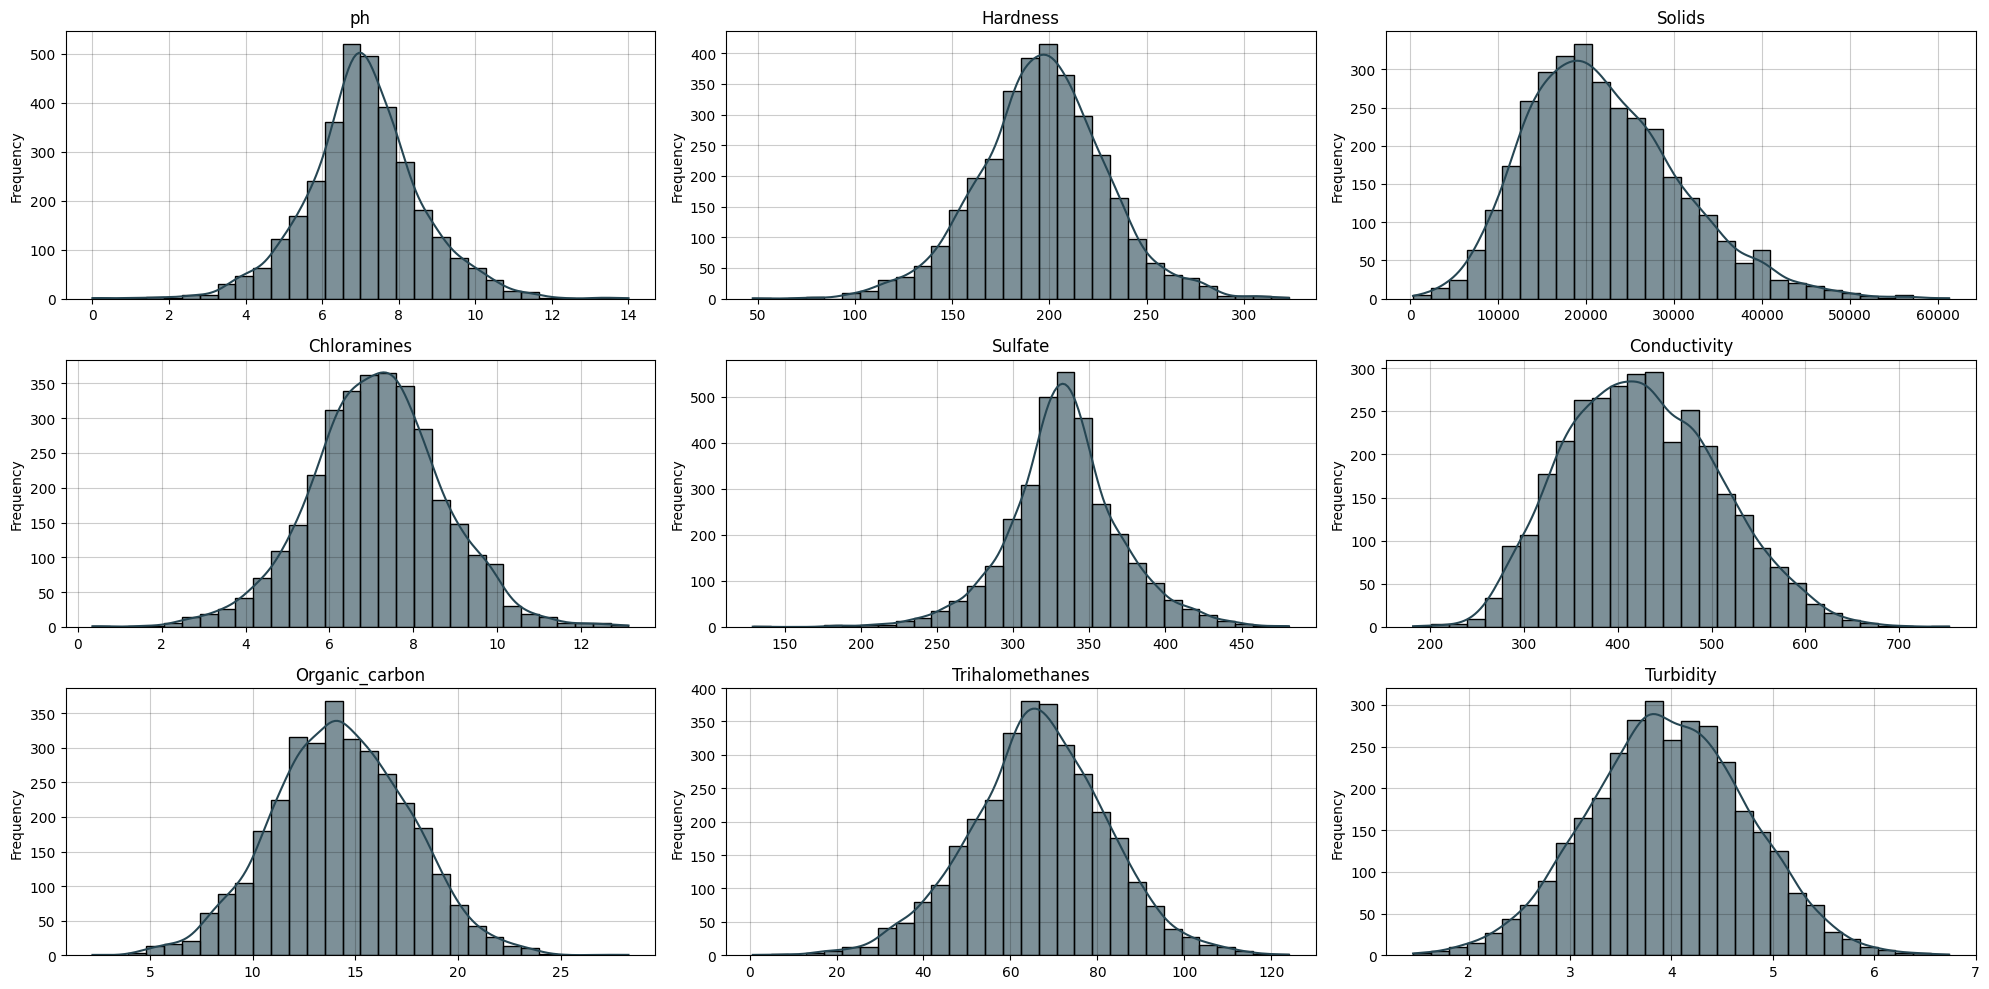

In [32]:
columns = Data3_Clean_After_KNN.columns[:-1]

fig, axes = plt.subplots(3, 3, figsize=(20, 10))
axes = axes.flatten()

for i, col in enumerate(columns):

    axes[i].set_facecolor("white")

    sns.histplot(
        Data3_Clean_After_KNN[col],
        bins=30,
        kde=True,
        color="#264653",
        alpha=0.6,
        ax=axes[i]
    )

    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frequency")

    axes[i].grid(alpha=0.2, color="Black")

plt.tight_layout()
plt.show()

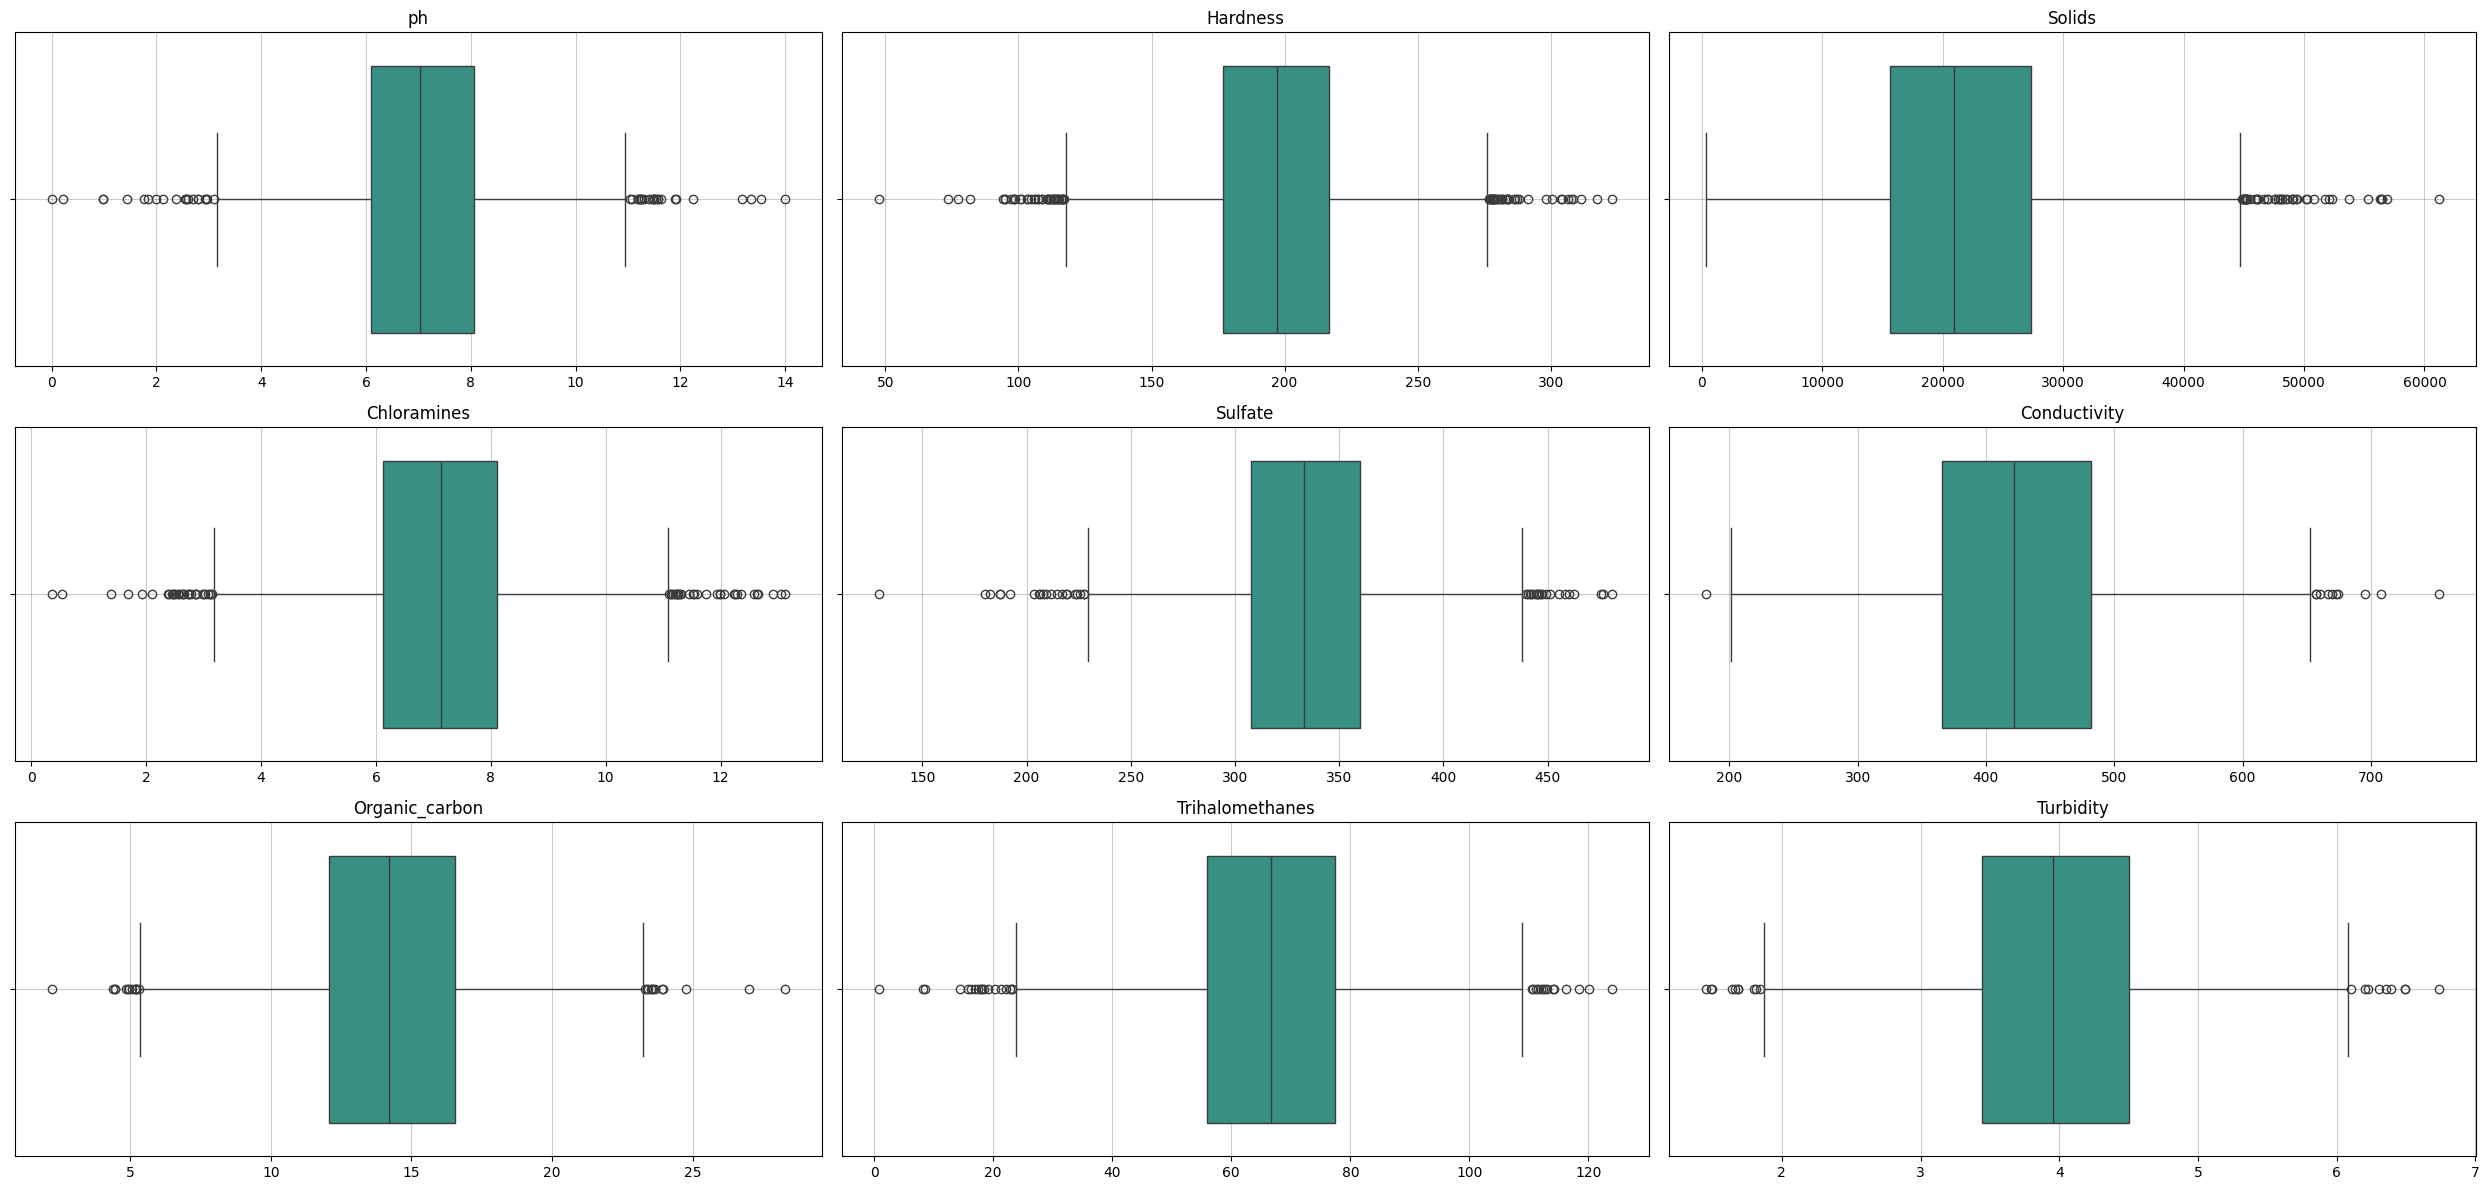

In [33]:
columns = Data3_Clean_After_KNN.columns[:-1] # All columns except the last column

fig, axes = plt.subplots(3, 3, figsize=(25, 12))
axes = axes.flatten()

for i, col in enumerate(columns):

    axes[i].set_facecolor("white")

    sns.boxplot(
        x=Data[col],
        color="#2A9D8F",
        ax=axes[i]
    )

    axes[i].set_title(col)
    axes[i].set_xlabel("")

    axes[i].grid(alpha=0.2, color="Black")

plt.tight_layout()
plt.show()

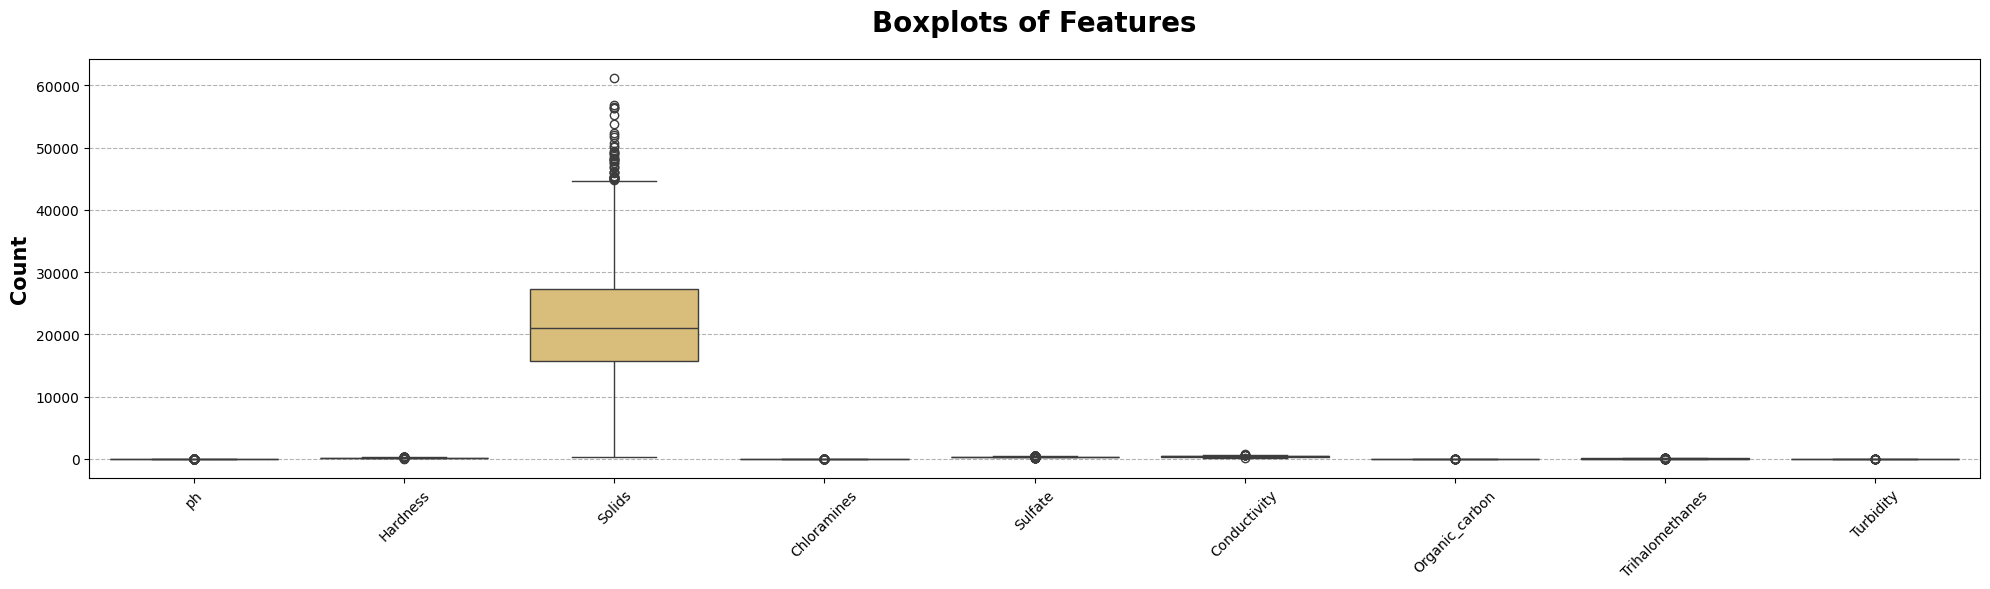

In [34]:
plt.figure(figsize=(20, 6))

ax = sns.boxplot(
    data=Data3_Clean_After_KNN.iloc[:, :-1],
    color="#E9C46A"
)

ax.set_facecolor("white")

ax.grid(
    True,
    axis="y",
    color="black",
    alpha=0.3,
    linestyle="--"
)

plt.xticks(rotation=45)

plt.ylabel(
    "Count",
    fontsize=15,
    fontweight="bold"
    )

plt.title(
    "Boxplots of Features", 
    fontsize=20, 
    fontweight="bold", 
    pad=20)

plt.tight_layout()
plt.show()

> ##### # As we have already examined and see here, the Solid has very abnormal outliers.

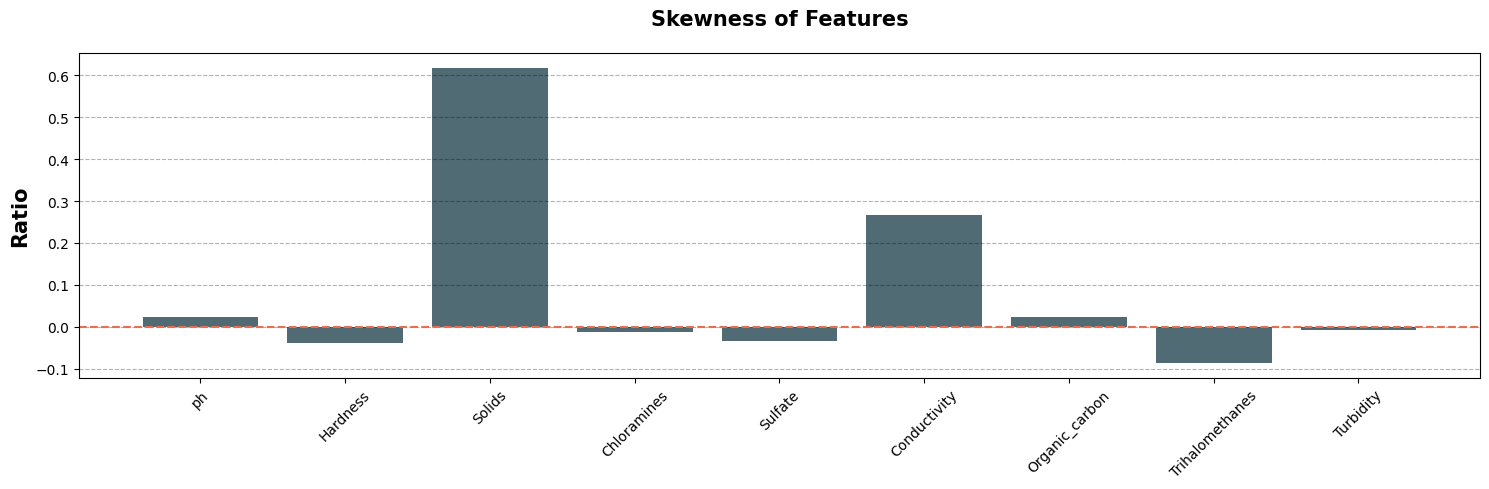

In [35]:
skew = Data3_Clean_After_KNN.iloc[:, :-1].skew()

plt.figure(figsize=(15,5))
ax = plt.gca()
ax.set_facecolor("white")


plt.bar(
    skew.index, skew.values, 
    color="#264653",
    alpha=0.8
    )

plt.axhline(0, color='#E76F51', linestyle='--')
plt.xticks(rotation=45)

plt.grid(
    axis="y",
    color="black",
    alpha=0.3,
    linestyle="--"
)

plt.ylabel(
    "Ratio",
    fontsize=15,
    fontweight="bold"
    )

plt.title(
    "Skewness of Features",
    fontsize=15,
    fontweight="bold",
    pad=20
    )
plt.tight_layout()
plt.show()

> ##### This plot shows the skewness of our data relative to the symmetric case. It is obvious that theSolids and after that, Conductivity tends towards very large numbers.

In [36]:
summary = pd.DataFrame({
    'Count': Data3_Clean_After_KNN.iloc[:, :-1].count(),
    'Mean': Data3_Clean_After_KNN.iloc[:, :-1].mean(),
    'Median': Data3_Clean_After_KNN.iloc[:, :-1].median(),
    'Std': Data3_Clean_After_KNN.iloc[:, :-1].std(),
    'Min': Data3_Clean_After_KNN.iloc[:, :-1].min(),
    'Q1': Data3_Clean_After_KNN.iloc[:, :-1].quantile(0.25),
    'Q3': Data3_Clean_After_KNN.iloc[:, :-1].quantile(0.75),
    'Max': Data3_Clean_After_KNN.iloc[:, :-1].max(),
    'IQR': Data3_Clean_After_KNN.iloc[:, :-1].quantile(0.75) - Data3_Clean_After_KNN.iloc[:, :-1].quantile(0.25),
    'Lower_Bound': Data3_Clean_After_KNN.iloc[:, :-1].quantile(0.25) - 1.5 * (Data3_Clean_After_KNN.iloc[:, :-1].quantile(0.75) - Data3_Clean_After_KNN.iloc[:, :-1].quantile(0.25)),
    'Upper_Bound': Data3_Clean_After_KNN.iloc[:, :-1].quantile(0.75) + 1.5 * (Data3_Clean_After_KNN.iloc[:, :-1].quantile(0.75) - Data3_Clean_After_KNN.iloc[:, :-1].quantile(0.25)),
    'Skewness': Data3_Clean_After_KNN.iloc[:, :-1].skew(),
    'Kurtosis': Data3_Clean_After_KNN.iloc[:, :-1].kurt()
})

summary = summary.round(3)

summary

,Count,Mean,Median,Std,Min,Q1,Q3,Max,IQR,Lower_Bound,Upper_Bound,Skewness,Kurtosis
ph,3267,7.084,7.052,1.486,0.000,6.253,7.917,14.000,1.664,3.756,10.414,0.024,1.210
Hardness,3267,196.366,196.953,32.894,47.432,176.847,216.660,323.124,39.813,117.128,276.380,-0.038,0.617
Solids,3267,22013.424,20965.478,8760.888,320.943,15665.107,27334.162,61227.196,11669.055,-1838.476,44837.745,0.618,0.444
Chloramines,3267,7.123,7.130,1.584,0.352,6.128,8.115,13.127,1.987,3.149,11.095,-0.013,0.592
Sulfate,3267,333.691,333.289,36.924,129.000,313.936,352.824,481.031,38.887,255.606,411.154,-0.033,1.429
Conductivity,3267,426.144,421.880,80.788,181.484,365.730,481.609,753.343,115.879,191.910,655.428,0.266,-0.272
Organic_carbon,3267,14.288,14.222,3.309,2.200,12.066,16.559,28.300,4.493,5.326,23.299,0.024,0.046
Trihalomethanes,3267,66.409,66.589,15.825,0.738,56.516,76.796,124.000,20.280,26.095,107.217,-0.086,0.371
Turbidity,3267,3.967,3.955,0.781,1.450,3.440,4.500,6.739,1.061,1.849,6.092,-0.008,-0.063


> ##### In this table, we take a closer look at outliers with Lower/Upper Bound

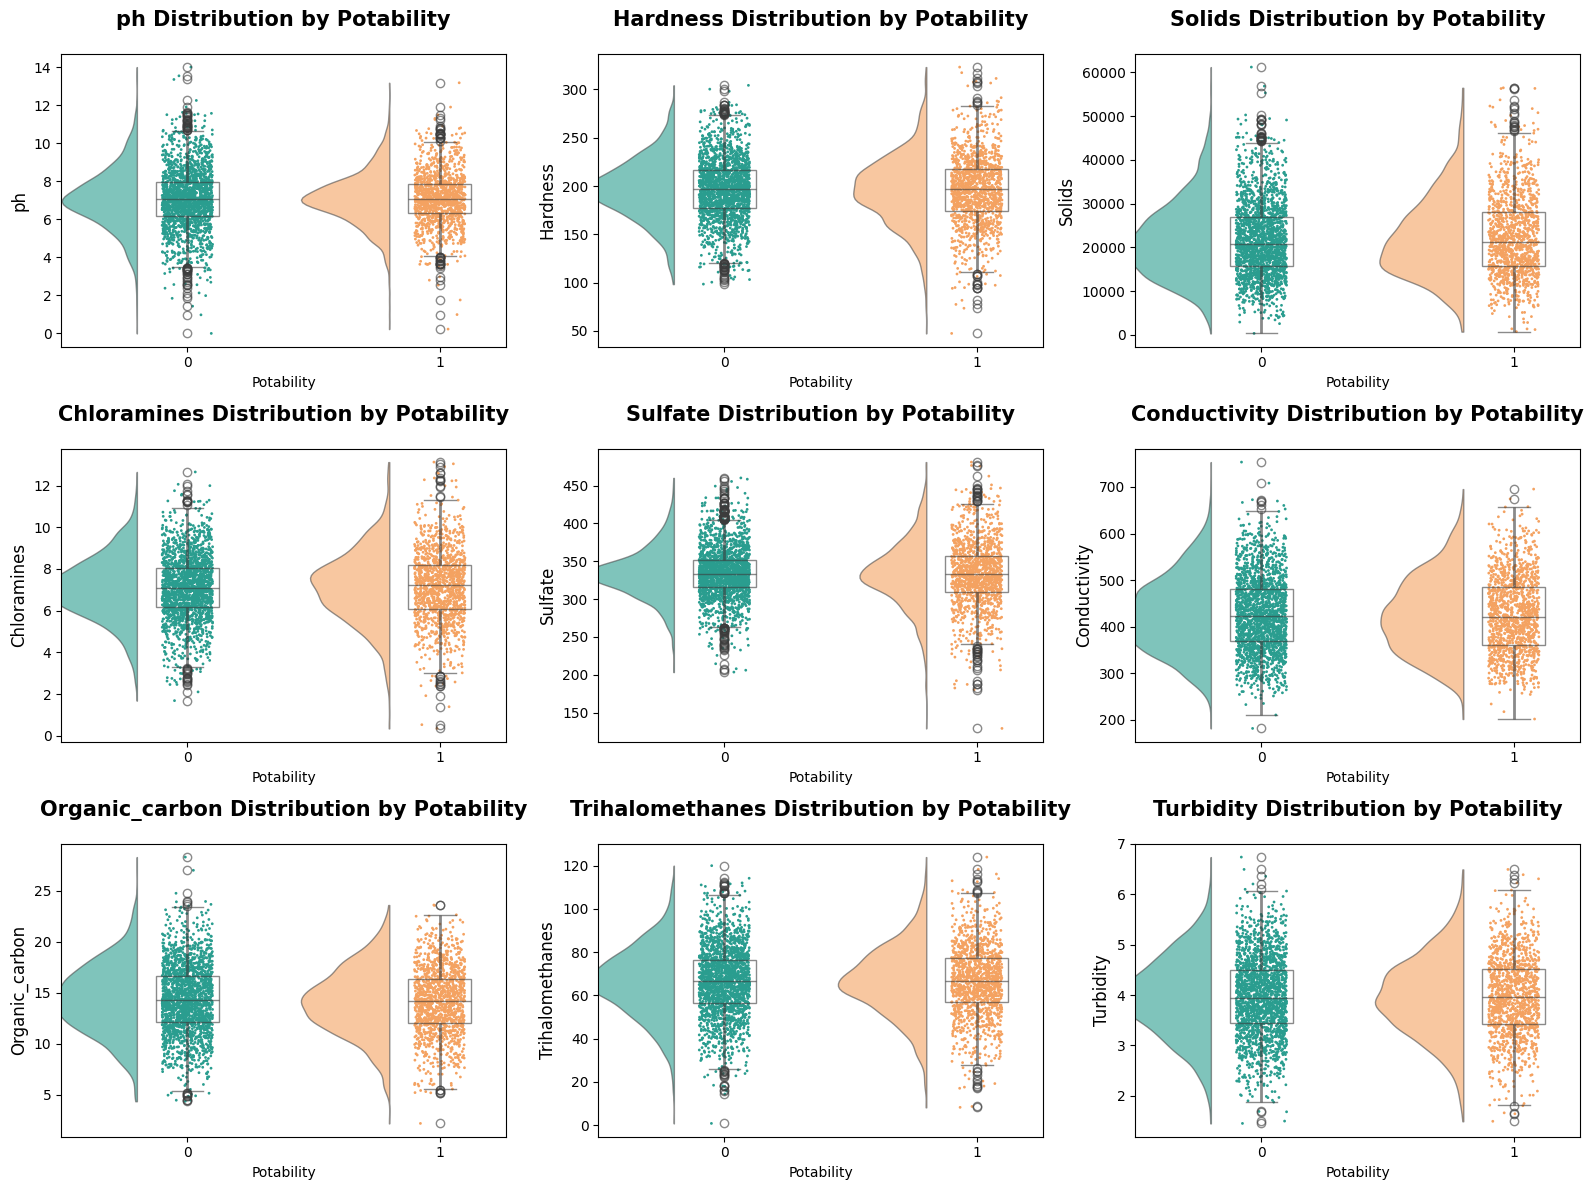

In [37]:
features = Data3_Clean_After_KNN.columns[:-1]  # All columns except the last one (Potability)

fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for ax, feature in zip(axes.flat, features):

    pt.RainCloud(
        x='Potability',
        y=feature,
        data=Data3_Clean_After_KNN,
        palette=["#2A9D8F","#F4A261"],
        width_viol=0.7,
        width_box=0.25,
        point_size=2,
        alpha=0.6,
        orient='v',
        ax=ax
    )

    ax.set_title(
        f'{feature} Distribution by Potability',
        fontsize=15,
        fontweight="bold",
        pad=20
        )
    
    ax.set_xlabel('Potability')

    ax.set_ylabel(
        feature,
        fontsize=12
        )

plt.tight_layout()
plt.show()

In [38]:
# Combining Pearson/Spearman correlation and Mutual Information for Feature–Target Association

# 1. Pearson Correlation
pearson_corr = (
    Data3_Clean_After_KNN
    .corr(method="pearson", numeric_only=True)["Potability"]
    .drop("Potability")
    .sort_values(key=abs, ascending=False)
)

# 2. Spearman Correlation
spearman_corr = (
    Data3_Clean_After_KNN
    .corr(method="spearman", numeric_only=True)["Potability"]
    .drop("Potability")
    .sort_values(key=abs, ascending=False)
)

# 3. Mutual Information (ranking / exploratory signal)

X = Data3_Clean_After_KNN.drop(columns="Potability")
y = Data3_Clean_After_KNN["Potability"]

mi = mutual_info_classif(
    X,
    y,
    random_state=42
)

mi_df = pd.DataFrame({
    "Feature": X.columns,
    "Mutual Information": mi
}).sort_values(
    by="Mutual Information",
    ascending=False
)

comparison = pd.concat(
    [
        pearson_corr.rename("Pearson"),
        spearman_corr.rename("Spearman"),
        mi_df.set_index("Feature")["Mutual Information"]
    ],
    axis=1
)

comparison

,Pearson,Spearman,Mutual Information
Solids,0.034327,0.026416,0.000065
Organic_carbon,-0.031821,-0.028720,0.002539
Chloramines,0.023779,0.025117,0.000000
Sulfate,-0.019580,-0.011821,0.016650
Hardness,-0.012768,-0.009466,0.026957
Conductivity,-0.008150,-0.010520,0.006791
Trihalomethanes,0.007540,0.005516,0.000000
ph,-0.001841,0.000270,0.000000
Turbidity,0.001792,0.001365,0.003477


> ##### None of the individual features show a strong linear or monotonic correlation with Potability; 
> ##### Pearson and Spearman correlation coefficients are close to zero for almost all features. 
> ##### However, Mutual Information scores are relatively higher for the features Hardness and Sulfate, suggesting the possibility of more complex, nonlinear dependencies. 
> ##### Based on this, these two features (Hardness and Sulfate) should be further analyzed in the next EDA steps using nonlinear visualizations and by examining their interactions with other features. 
> ##### Importantly, Potability is likely not determined by any single feature alone but rather by interactions or combinations of multiple features.

> ##### So, base in terms of Mutual Information:
>> Hardness > Sulfate > Conductivity > Turbidity > Organic_carbon > Solids ≈ 0
> ##### So if we want to prioritize for EDA to continue:
>> Hardness/Sulfate - Conductivity/Turbidity/Organic_carbon - Solids/Chloramines/Trihalomethanes/ph

# ✅Features relations with Potability     

Potability=0: 1990 (60.91%)
Potability=1: 1277 (39.09%)


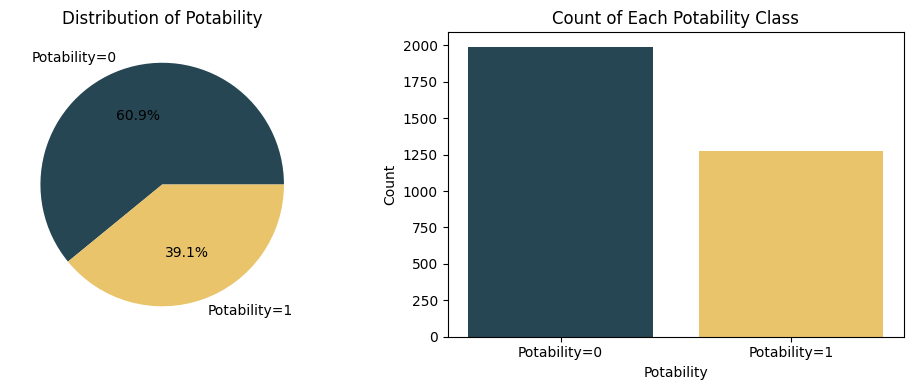

In [39]:
# Count occurrences of each class

Count = Data3_Clean_After_KNN["Potability"].value_counts()

# Get counts for Potability=0 and Potability=1
Potability_0 = Count.get(0, 0)
Potability_1 = Count.get(1, 0)

# Calculate total count
Total_Count = Potability_0 + Potability_1

# Calculate percentages
Potability_0_percent = (Potability_0 / Total_Count) * 100
Potability_1_percent = (Potability_1 / Total_Count) * 100

# Print counts and percentages
print(f"Potability=0: {Potability_0} ({Potability_0_percent:.2f}%)")
print(f"Potability=1: {Potability_1} ({Potability_1_percent:.2f}%)")

# Prepare data for pie chart
percentage_data = [Potability_0_percent, Potability_1_percent]

# Create a figure with subplots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))


# Create pie chart on the first subplot
axes[0].pie(
    percentage_data, 
    labels=['Potability=0', 'Potability=1'], 
    autopct='%1.1f%%',
    colors=["#264653","#E9C46A"]
    )

axes[0].set_title('Distribution of Potability')

# Create count plot on the second subplot
axes[1].bar(
    ['Potability=0', 'Potability=1'], 
    [Potability_0, Potability_1],
    color=["#264653","#E9C46A"]
    )

axes[1].set_title('Count of Each Potability Class')
axes[1].set_xlabel('Potability')
axes[1].set_ylabel('Count')

# Adjust layout
plt.tight_layout()
plt.show()

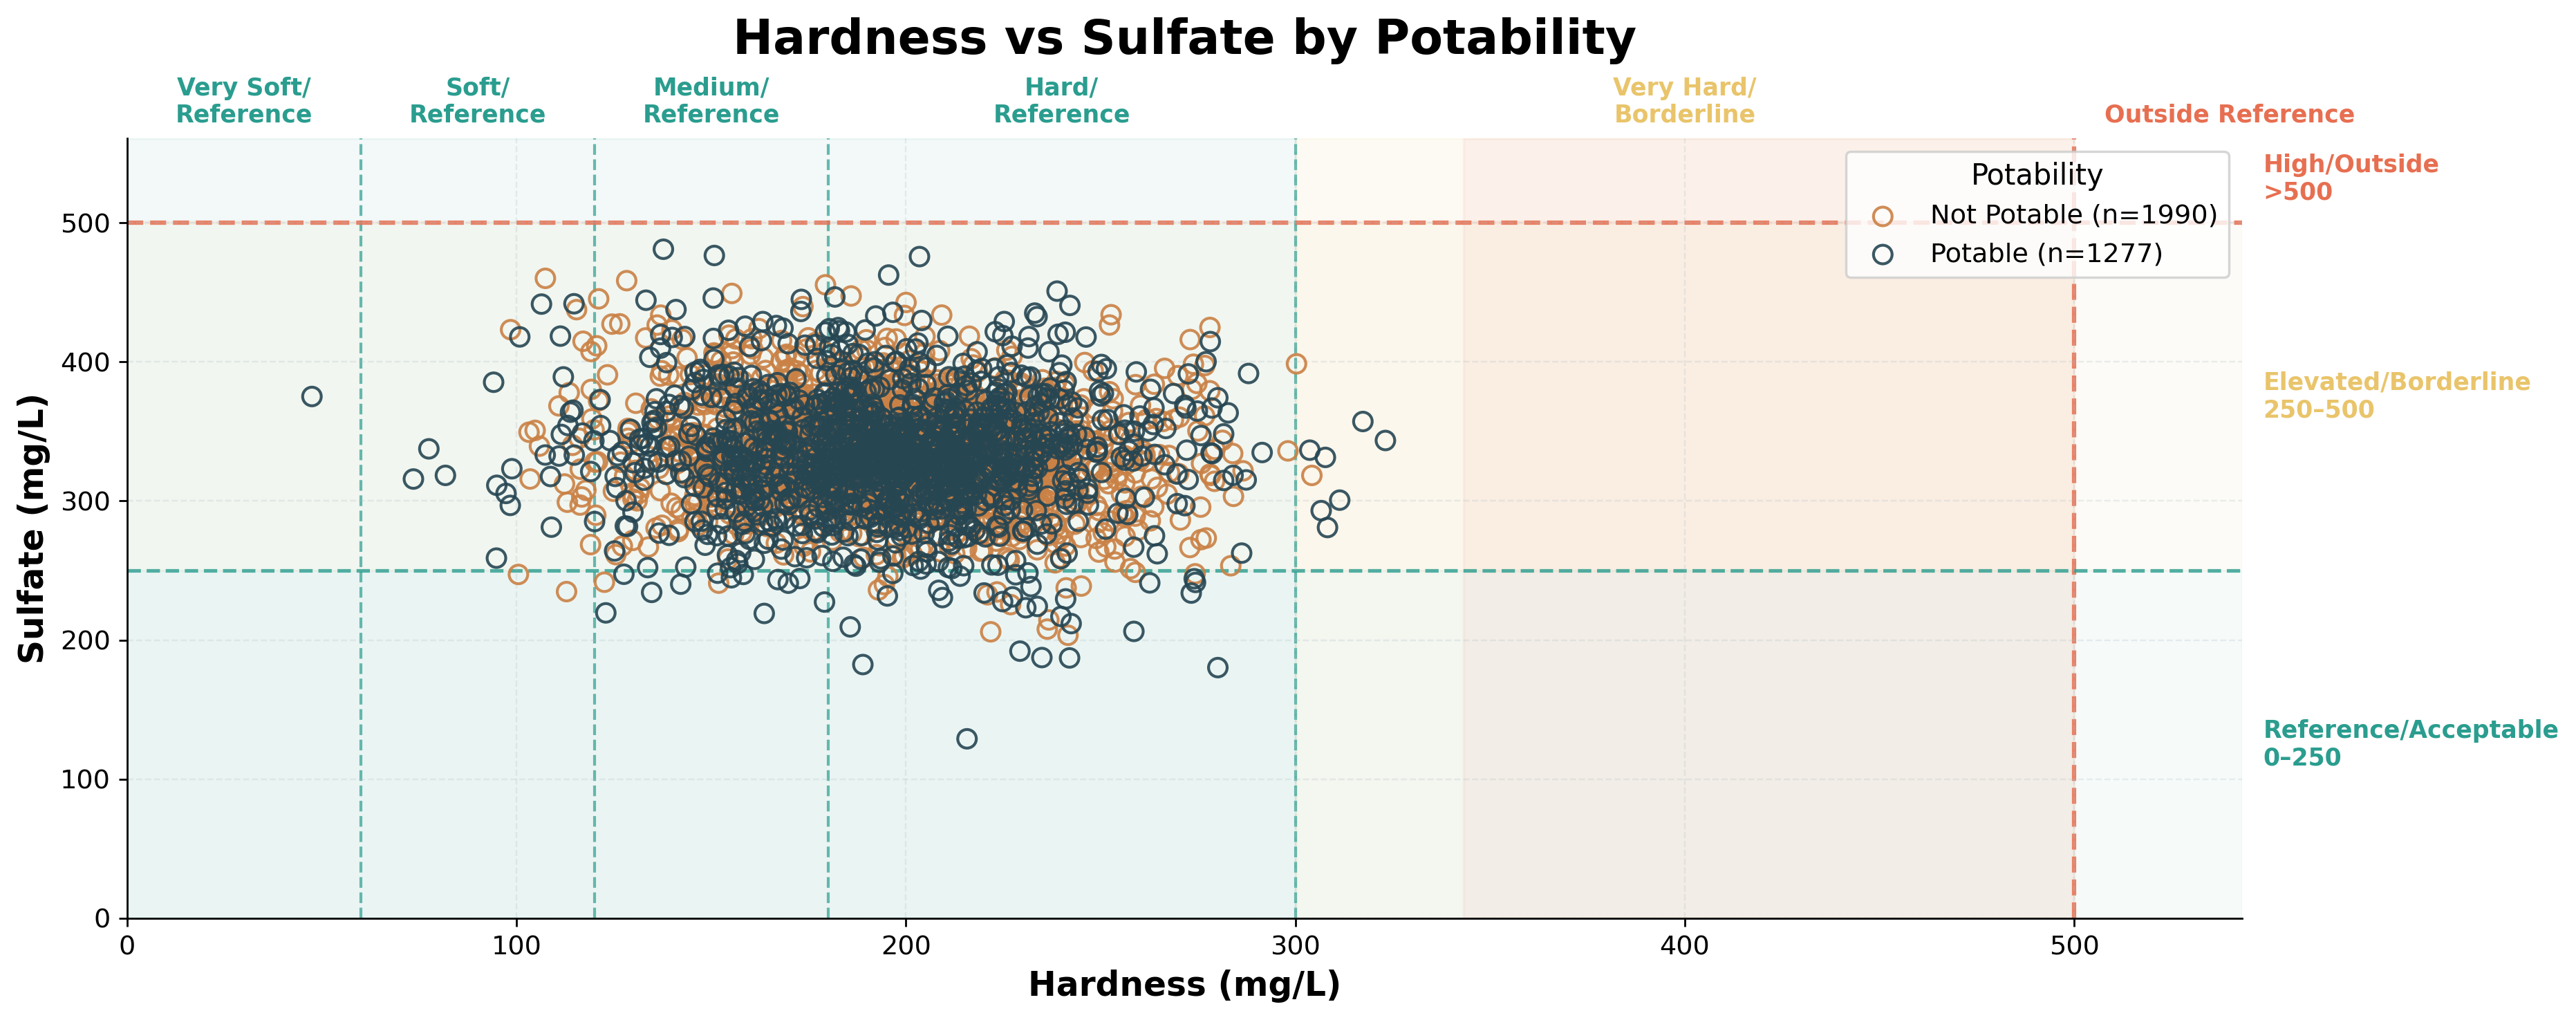

In [40]:
# df = Data3_Clean_After_KNN

not_potable = Data3_Clean_After_KNN[Data3_Clean_After_KNN["Potability"] == 0]
potable = Data3_Clean_After_KNN[Data3_Clean_After_KNN["Potability"] == 1]

# COLORS

COLOR_NOT_POTABLE = "#CA8145"
COLOR_POTABLE = "#264653"

COLOR_NORMAL = "#2A9D8F"
COLOR_BORDERLINE = "#E9C46A"
COLOR_OUTSIDE = "#E76F51"

TEXT_COLOR = "#000000"
GRID_COLOR = "#B0BEC5"


fig, ax = plt.subplots(
    figsize=(15, 6),
    dpi=250
)

# BACKGROUND ZONES — HARDNESS

# 0–300 : Reference / soft -  Medium - Hard
ax.axvspan(
    0, 300,
    color=COLOR_NORMAL,
    alpha=0.06,
    zorder=0
)

# 300–500 : Borderline / High
ax.axvspan(
    300, 500,
    color=COLOR_BORDERLINE,
    alpha=0.07,
    zorder=0
)

# >500 : Outside reference
ax.axvspan(
    500,
    Data3_Clean_After_KNN["Hardness"].max() + 20,
    color=COLOR_OUTSIDE,
    alpha=0.06,
    zorder=0
)

# BACKGROUND ZONES — SULFATE

# 0–250 : Reference / Acceptable

ax.axhspan(
    0, 250,
    color=COLOR_NORMAL,
    alpha=0.04,
    zorder=0
)

# 250–500 : Elevated / Borderline

ax.axhspan(
    250, 500,
    color=COLOR_BORDERLINE,
    alpha=0.05,
    zorder=0
)

# >500 : High / Outside reference

ax.axhspan(
    500,
    Data3_Clean_After_KNN["Sulfate"].max() + 20,
    color=COLOR_OUTSIDE,
    alpha=0.05,
    zorder=0
)

ax.scatter(
    not_potable["Hardness"],
    not_potable["Sulfate"],
    s=60,
    alpha=0.90,
    marker="o",
    color=COLOR_NOT_POTABLE,
    facecolors="none",
    edgecolors=COLOR_NOT_POTABLE,
    linewidths=1.2,
    label=f"Not Potable (n={len(not_potable)})",
    zorder=3
)

ax.scatter(
    potable["Hardness"],
    potable["Sulfate"],
    s=60,
    alpha=0.90,
    marker="o",
    color=COLOR_POTABLE,
    facecolors="none",
    edgecolors=COLOR_POTABLE,
    linewidths=1.2,
    label=f"Potable (n={len(potable)})",
    zorder=3
)

# HARDNESS REFERENCE LINES

for value in [60, 120, 180, 300]:
    ax.axvline(
        value,
        color=COLOR_NORMAL,
        linestyle="--",
        linewidth=1.2,
        alpha=0.7,
        zorder=1
    )

ax.axvline(
    500,
    color=COLOR_OUTSIDE,
    linestyle="--",
    linewidth=1.8,
    alpha=0.85,
    zorder=1
)

# SULFATE REFERENCE

ax.axhline(
    250,
    color=COLOR_NORMAL,
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    zorder=1
)

ax.axhline(
    500,
    color=COLOR_OUTSIDE,
    linestyle="--",
    linewidth=1.8,
    alpha=0.85,
    zorder=1
)

# HARDNESS LABELS

ax.text(
    30, 1.02,
    "Very Soft/\nReference",
    transform=ax.get_xaxis_transform(),
    ha="center",
    fontsize=10,
    fontweight="bold",
    color=COLOR_NORMAL
)

ax.text(
    90, 1.02,
    "Soft/\nReference",
    transform=ax.get_xaxis_transform(),
    ha="center",
    fontsize=10,
    fontweight="bold",
    color=COLOR_NORMAL
)

ax.text(
    150, 1.02,
    "Medium/\nReference",
    transform=ax.get_xaxis_transform(),
    ha="center",
    fontsize=10,
    fontweight="bold",
    color=COLOR_NORMAL
)

ax.text(
    240, 1.02,
    "Hard/\nReference",
    transform=ax.get_xaxis_transform(),
    ha="center",
    fontsize=10,
    fontweight="bold",
    color=COLOR_NORMAL
)

ax.text(
    400, 1.02,
    "Very Hard/\nBorderline",
    transform=ax.get_xaxis_transform(),
    ha="center",
    fontsize=10,
    fontweight="bold",
    color=COLOR_BORDERLINE
)

ax.text(
    540, 1.02,
    "Outside Reference",
    transform=ax.get_xaxis_transform(),
    ha="center",
    fontsize=10,
    fontweight="bold",
    color=COLOR_OUTSIDE
)

# SULFATE LABELS — RIGHT

ax.text(
    1.01, 125,
    "Reference/Acceptable\n0–250",
    transform=ax.get_yaxis_transform(),
    va="center",
    fontsize=10,
    color=COLOR_NORMAL,
    fontweight="bold"
)

ax.text(
    1.01, 375,
    "Elevated/Borderline\n250–500",
    transform=ax.get_yaxis_transform(),
    va="center",
    fontsize=10,
    color=COLOR_BORDERLINE,
    fontweight="bold"
)

ax.text(
    1.01, 550,
    "High/Outside\n>500",
    transform=ax.get_yaxis_transform(),
    va="top",
    fontsize=10,
    color=COLOR_OUTSIDE,
    fontweight="bold"
)

# AXIS

ax.set_xlabel(
    "Hardness (mg/L)",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel(
    "Sulfate (mg/L)",
    fontsize=14,
    fontweight="bold"
)

ax.set_title(
    "Hardness vs Sulfate by Potability",
    fontsize=20,
    fontweight="bold",
    color=TEXT_COLOR,
    pad=35
)

# GRID

ax.grid(
    axis="both",
    linestyle="--",
    linewidth=0.7,
    color=GRID_COLOR,
    alpha=0.25
)

# SPINES

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# LEGEND

ax.legend(
    title="Potability",
    fontsize=11,
    title_fontsize=12,
    frameon=True,
    loc="upper right"
)

# LIMITS

ax.set_xlim(
    0,
    Data3_Clean_After_KNN["Hardness"].max() + 220
)

ax.set_ylim(
    0,
    Data3_Clean_After_KNN["Sulfate"].max() + 80
)

# TICKS

ax.tick_params(
    axis="both",
    labelsize=11
)


plt.tight_layout()
plt.show()

> ##### The points of the two groups overlap in a large part of the Hardness/Sulfate space.
> ##### Hardness/Sulfate alone does not establish a clear boundary for potability.
> ##### The combination of these two features did not create a clear two-class pattern.
> ##### These two features, as bivariate and independent, do not create a clear separation between potable and non-potable water.

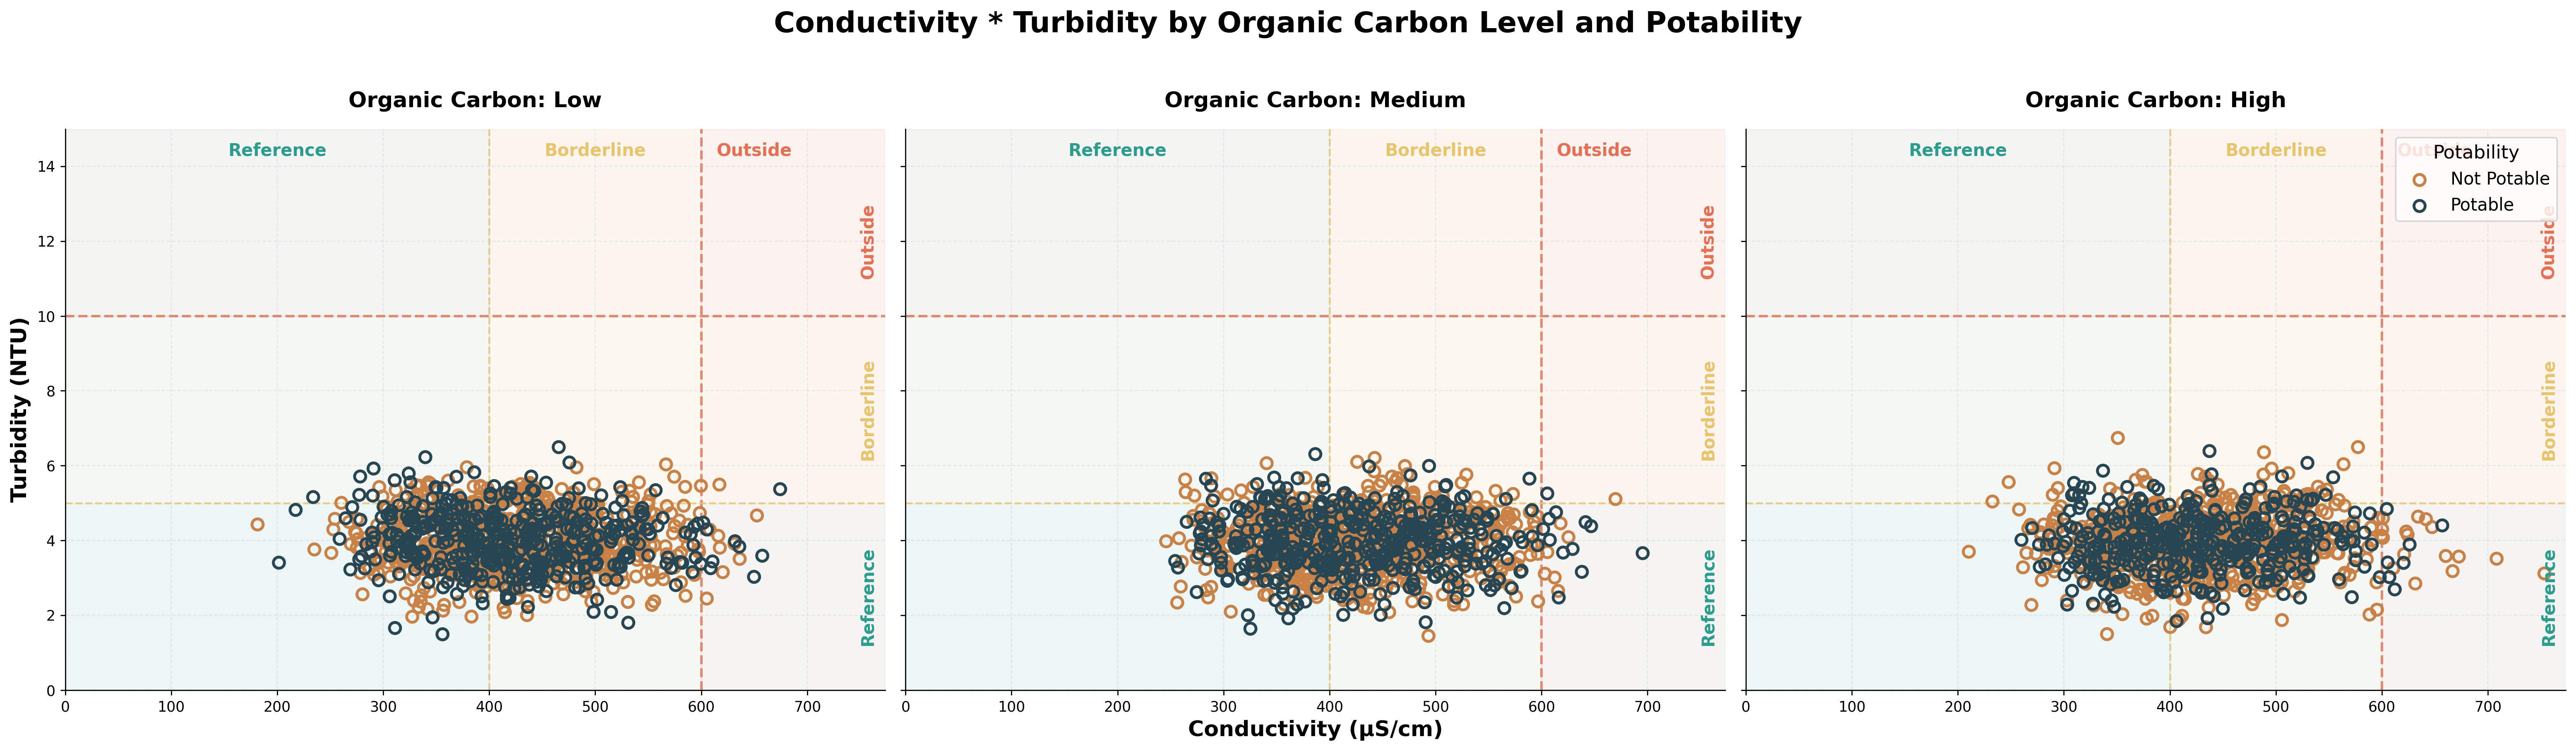

In [41]:
df = Data3_Clean_After_KNN.copy()       # Because we want to classify Organic_carbon, we make a copy of the dataset.

# Divide Organic Carbon into 3 groups

df["Organic_Carbon_Level"] = pd.qcut(
    df["Organic_carbon"],
    q=3,
    labels=["Low", "Medium", "High"]
)

# COLORS

COLOR_NOT_POTABLE = "#CA8145"
COLOR_POTABLE = "#264653"

COLOR_NORMAL = "#2A9D8F"
COLOR_BORDERLINE = "#E9C46A"
COLOR_OUTSIDE = "#E76F51"

TEXT_COLOR = "#000000"
GRID_COLOR = "#B0BEC5"

# FIGURE

fig, axes = plt.subplots(
    1,
    3,
    figsize=(25, 7),
    dpi=250,
    sharex=True,
    sharey=True
)

levels = ["Low", "Medium", "High"]

# COMMON AXIS LIMITS

x_min = 0

x_max = max(
    700,
    df["Conductivity"].max() + 20
)

y_min = 0

y_max = max(
    15,
    df["Turbidity"].max() + 1
)

# PLOT

for ax, level in zip(axes, levels):

    subset = df[
        df["Organic_Carbon_Level"] == level
    ]

    not_potable = subset[
        subset["Potability"] == 0
    ]

    potable = subset[
        subset["Potability"] == 1
    ]

    # CONDUCTIVITY BACKGROUND

    ax.axvspan(
        0,
        400,
        color=COLOR_NORMAL,
        alpha=0.045,
        zorder=0
    )

    ax.axvspan(
        400,
        600,
        color=COLOR_BORDERLINE,
        alpha=0.05,
        zorder=0
    )

    ax.axvspan(
        600,
        x_max,
        color=COLOR_OUTSIDE,
        alpha=0.045,
        zorder=0
    )

    # TURBIDITY BACKGROUND

    ax.axhspan(
        0,
        5,
        color=COLOR_NORMAL,
        alpha=0.035,
        zorder=0
    )

    ax.axhspan(
        5,
        10,
        color=COLOR_BORDERLINE,
        alpha=0.045,
        zorder=0
    )

    ax.axhspan(
        10,
        y_max,
        color=COLOR_OUTSIDE,
        alpha=0.04,
        zorder=0
    )

    # CONDUCTIVITY REFERENCE LINES

    ax.axvline(
        400,
        color=COLOR_BORDERLINE,
        linestyle="--",
        linewidth=1.3,
        alpha=0.8,
        zorder=1
    )

    ax.axvline(
        600,
        color=COLOR_OUTSIDE,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
        zorder=1
    )

    # TURBIDITY REFERENCE LINES

    ax.axhline(
        5,
        color=COLOR_BORDERLINE,
        linestyle="--",
        linewidth=1.3,
        alpha=0.8,
        zorder=1
    )

    ax.axhline(
        10,
        color=COLOR_OUTSIDE,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
        zorder=1
    )

    # RANGE LABELS - CONDUCTIVITY

    ax.text(
        200,
        y_max - 0.35,
        "Reference",
        ha="center",
        va="top",
        fontsize=12,
        fontweight="bold",
        color=COLOR_NORMAL,
        zorder=5
    )

    ax.text(
        500,
        y_max - 0.35,
        "Borderline",
        ha="center",
        va="top",
        fontsize=12,
        fontweight="bold",
        color=COLOR_BORDERLINE,
        zorder=5
    )

    ax.text(
        650,
        y_max - 0.35,
        "Outside",
        ha="center",
        va="top",
        fontsize=12,
        fontweight="bold",
        color=COLOR_OUTSIDE,
        zorder=5
    )

    # RANGE LABELS - TURBIDITY

    ax.text(
        x_max - 8,
        2.5,
        "Reference",
        ha="right",
        va="center",
        fontsize=12,
        fontweight="bold",
        color=COLOR_NORMAL,
        rotation=90,
        zorder=5
    )

    ax.text(
        x_max - 8,
        7.5,
        "Borderline",
        ha="right",
        va="center",
        fontsize=12,
        fontweight="bold",
        color=COLOR_BORDERLINE,
        rotation=90,
        zorder=5
    )

    ax.text(
        x_max - 8,
        12,
        "Outside",
        ha="right",
        va="center",
        fontsize=12,
        fontweight="bold",
        color=COLOR_OUTSIDE,
        rotation=90,
        zorder=5
    )

    # NOT POTABLE

    ax.scatter(
        not_potable["Conductivity"],
        not_potable["Turbidity"],
        s=60,
        facecolors="none",
        edgecolors=COLOR_NOT_POTABLE,
        linewidths=2,
        alpha=1,
        marker="o",
        label="Not Potable",
        zorder=4
    )

    # POTABLE

    ax.scatter(
        potable["Conductivity"],
        potable["Turbidity"],
        s=60,
        facecolors="none",
        edgecolors=COLOR_POTABLE,
        linewidths=2,
        alpha=1,
        marker="o",
        label="Potable",
        zorder=4
    )

    # PANEL TITLE

    ax.set_title(
        f"Organic Carbon: {level}",
        fontsize=15,
        fontweight="bold",
        color=TEXT_COLOR,
        pad=15
    )

    # GRID

    ax.grid(
        linestyle="--",
        linewidth=0.7,
        color=GRID_COLOR,
        alpha=0.25,
        zorder=1
    )

    # SPINES

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # LIMITS

    ax.set_xlim(
        x_min,
        x_max
    )

    ax.set_ylim(
        y_min,
        y_max
    )

axes[0].set_ylabel(
    "Turbidity (NTU)",
    fontsize=15,
    fontweight="bold"
)

axes[1].set_xlabel(
    "Conductivity (μS/cm)",
    fontsize=15,
    fontweight="bold"
)


fig.suptitle(
    "Conductivity * Turbidity by Organic Carbon Level and Potability",
    fontsize=20,
    fontweight="bold",
    color=TEXT_COLOR,
    y=1.03
)

ax.legend(
    title="Potability",
    fontsize=12,
    title_fontsize=13,
    frameon=True,
    loc="upper right"
)


plt.tight_layout()

plt.show()

> ##### Conductivity + Turbidity + Organic_carbon alone do not create a clear separation between the two classes.
> ##### With increasing Organic Carbon, the distribution of points or the Potable/Not Potable ratio in specific areas did not change significantly, and there was no evidence of a strong interaction of Organic Carbon with these two features.
> ##### The three-way interaction between Conductivity, Turbidity, and Organic Carbon does not appear to provide a clear visual separation between potable and non-potable water samples. Although the reference ranges highlight regions of interest, substantial overlap between the two Potability classes remains across different Organic Carbon levels.

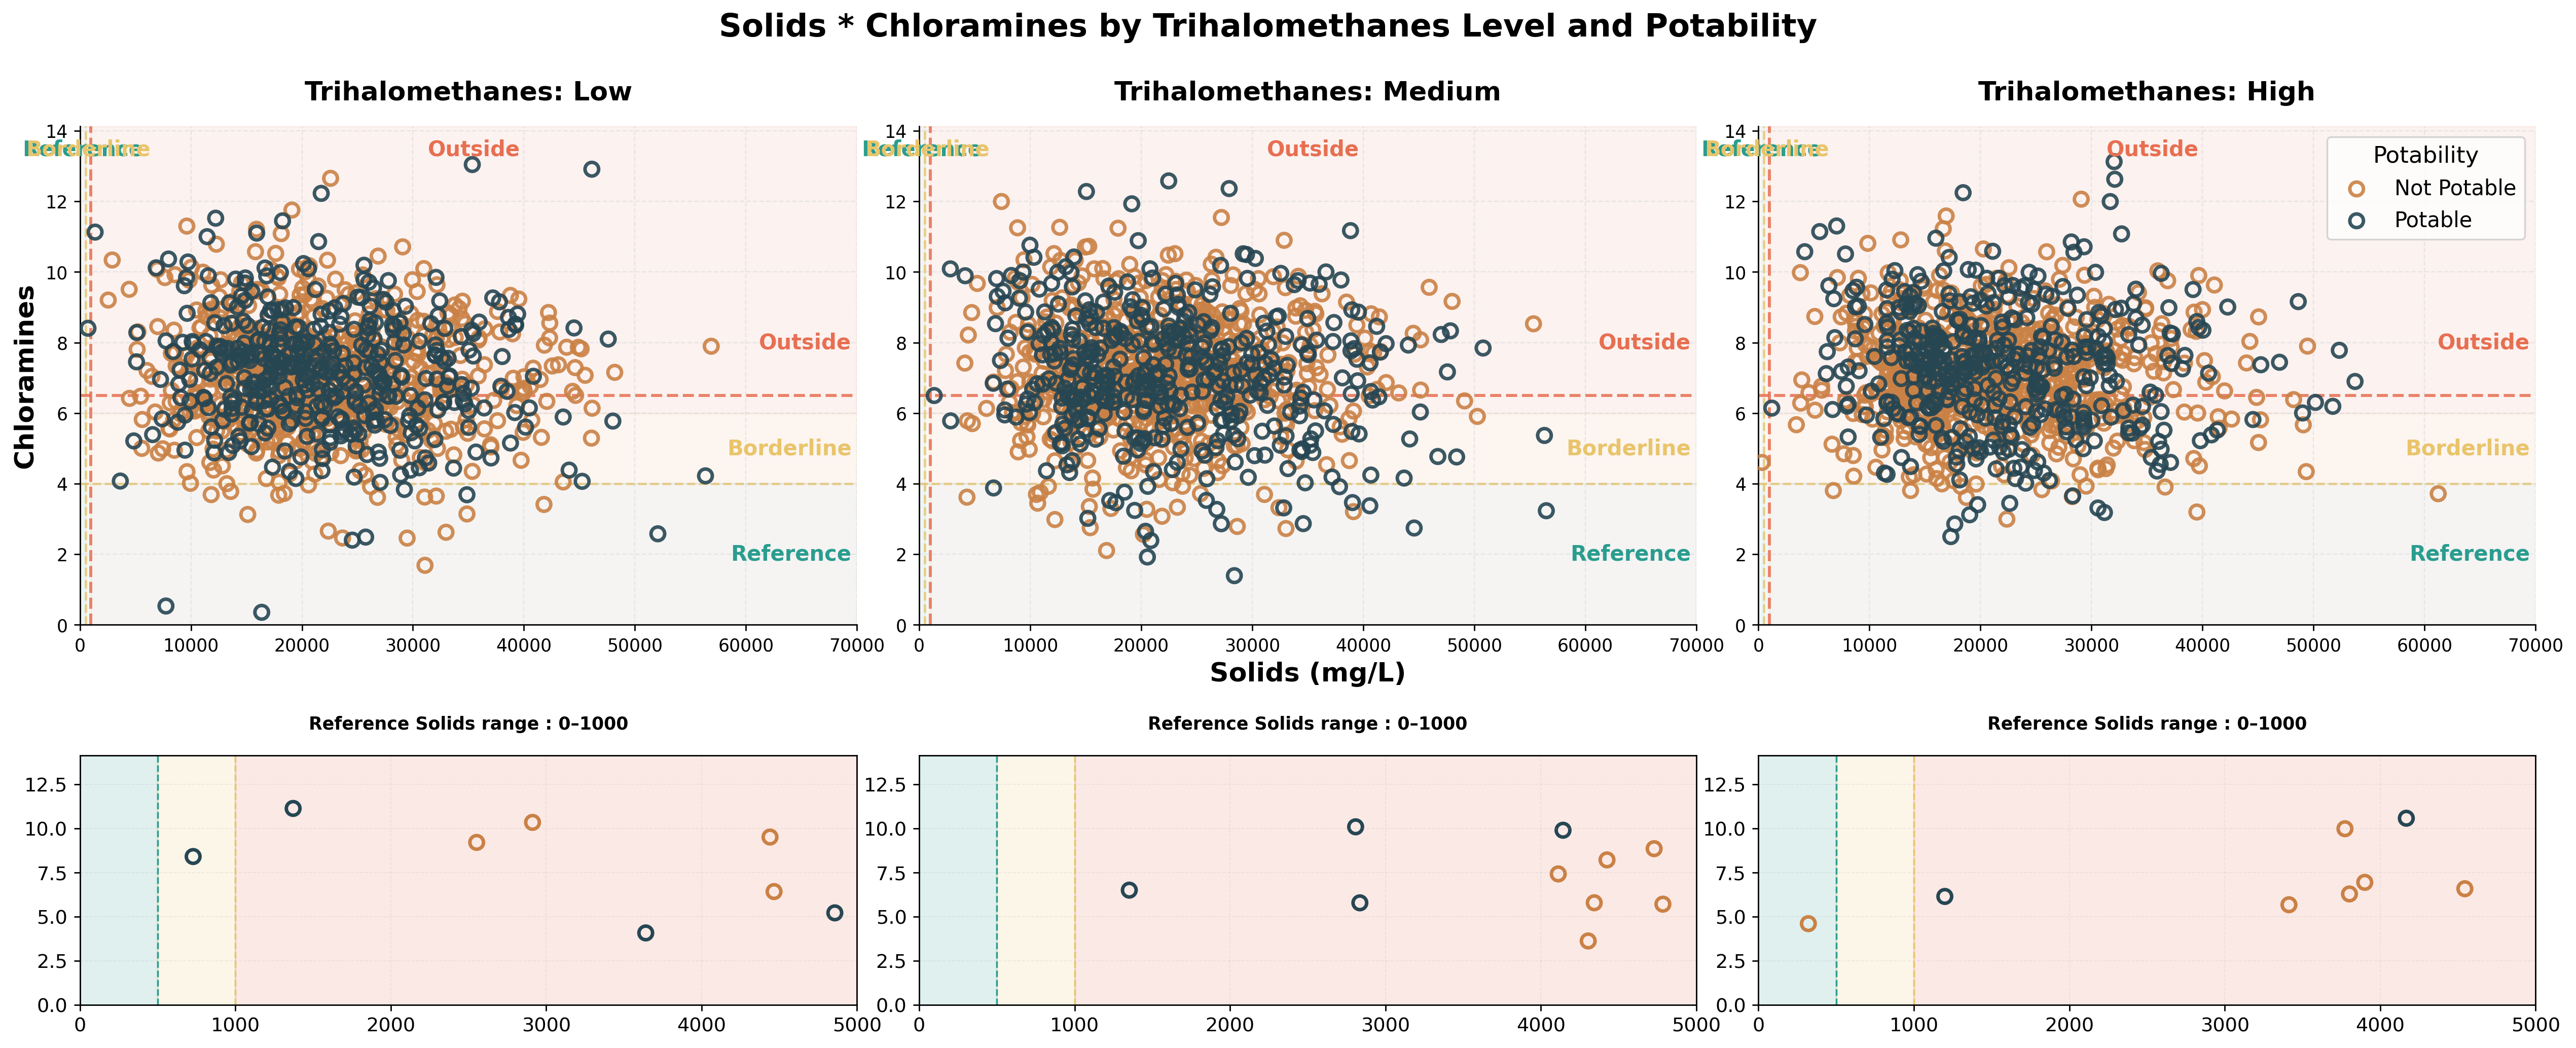

In [42]:
df = Data3_Clean_After_KNN.copy()  

# Divide Trihalomethanes into 3 groups
df["THM_Level"] = pd.qcut(
    df["Trihalomethanes"],
    q=3,
    labels=["Low", "Medium", "High"]
)

# COLORS

COLOR_NOT_POTABLE = "#CA8145"
COLOR_POTABLE = "#264653"

COLOR_NORMAL = "#2A9D8F"
COLOR_BORDERLINE = "#E9C46A"
COLOR_OUTSIDE = "#E76F51"

TEXT_COLOR = "#000000"
GRID_COLOR = "#B0BEC5"

# FIGURE

fig = plt.figure(
    figsize=(25, 9),
    dpi=250
)

gs = fig.add_gridspec(
    2,
    3,
    height_ratios=[8, 4],
    hspace=0.35,
    wspace=0.08
)

axes = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[0, 2])
]

inset_axes = [
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[1, 2])
]


levels = ["Low", "Medium", "High"]


# COMMON AXIS LIMITS

x_min = 0

x_max = max(
    70000,
    df["Solids"].max() + 2000
)

y_min = 0

y_max = max(
    12,
    df["Chloramines"].max() + 1
)

# MAIN PLOTS

for ax, level, inset in zip(
    axes,
    levels,
    inset_axes
):

    subset = df[
        df["THM_Level"] == level
    ]

    not_potable = subset[
        subset["Potability"] == 0
    ]

    potable = subset[
        subset["Potability"] == 1
    ]

    # SOLIDS BACKGROUND

    # Normal / Reference
    ax.axvspan(
        0,
        500,
        color=COLOR_NORMAL,
        alpha=0.045,
        zorder=0
    )

    # Borderline
    ax.axvspan(
        500,
        1000,
        color=COLOR_BORDERLINE,
        alpha=0.05,
        zorder=0
    )

    # Outside
    ax.axvspan(
        1000,
        x_max,
        color=COLOR_OUTSIDE,
        alpha=0.045,
        zorder=0
    )

    # CHLORAMINES BACKGROUND

    # Normal / Reference
    ax.axhspan(
        0,
        4,
        color=COLOR_NORMAL,
        alpha=0.035,
        zorder=0
    )

    # Borderline
    ax.axhspan(
        4,
        6,
        color=COLOR_BORDERLINE,
        alpha=0.045,
        zorder=0
    )

    # Outside
    ax.axhspan(
        6,
        y_max,
        color=COLOR_OUTSIDE,
        alpha=0.04,
        zorder=0
    )

    # SOLIDS REFERENCE LINES

    ax.axvline(
        500,
        color=COLOR_BORDERLINE,
        linestyle="--",
        linewidth=1.3,
        alpha=0.8,
        zorder=1
    )

    ax.axvline(
        1000,
        color=COLOR_OUTSIDE,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
        zorder=1
    )

    # CHLORAMINES REFERENCE LINES

    ax.axhline(
        4,
        color=COLOR_BORDERLINE,
        linestyle="--",
        linewidth=1.3,
        alpha=0.8,
        zorder=1
    )

    ax.axhline(
        6.5,
        color=COLOR_OUTSIDE,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
        zorder=1
    )

    # RANGE LABELS — SOLIDS

    ax.text(
        250,
        y_max - 0.35,
        "Reference",
        ha="center",
        va="top",
        fontsize=12,
        fontweight="bold",
        color=COLOR_NORMAL,
        zorder=5
    )

    ax.text(
        750,
        y_max - 0.35,
        "Borderline",
        ha="center",
        va="top",
        fontsize=12,
        fontweight="bold",
        color=COLOR_BORDERLINE,
        zorder=5
    )

    ax.text(
        (1000 + x_max) / 2,
        y_max - 0.35,
        "Outside",
        ha="center",
        va="top",
        fontsize=12,
        fontweight="bold",
        color=COLOR_OUTSIDE,
        zorder=5
    )

    # INSET — SOLIDS LOW RANGE

    inset.set_xlim(
        0,
        5000
    )

    inset.set_ylim(
        0,
        y_max
    )

    # Reference
    inset.axvspan(
        0,
        500,
        color=COLOR_NORMAL,
        alpha=0.15
    )

    # Borderline
    inset.axvspan(
        500,
        1000,
        color=COLOR_BORDERLINE,
        alpha=0.15
    )

    # Outside
    inset.axvspan(
        1000,
        5000,
        color=COLOR_OUTSIDE,
        alpha=0.15
    )
    # Reference lines

    inset.axvline(
        500,
        color=COLOR_NORMAL,
        linestyle="--",
        linewidth=1
    )

    inset.axvline(
        1000,
        color=COLOR_BORDERLINE,
        linestyle="--",
        linewidth=1
    )

    # Inset points

    inset.scatter(
        not_potable["Solids"],
        not_potable["Chloramines"],
        s=60,
        facecolors="none",
        edgecolors=COLOR_NOT_POTABLE,
        linewidths=2,
        alpha=1
    )

    inset.scatter(
        potable["Solids"],
        potable["Chloramines"],
        s=60,
        facecolors="none",
        edgecolors=COLOR_POTABLE,
        linewidths=2,
        alpha=1
    )

    inset.set_title(
        "Reference Solids range : 0–1000",
        fontsize=10,
        fontweight="bold",
        pad=15
    )

    inset.tick_params(
        labelsize=11
    )

    inset.grid(
        linestyle="--",
        linewidth=0.5,
        alpha=0.2
    )

    # RANGE LABELS — CHLORAMINES

    ax.text(
        x_max - 500,
        2,
        "Reference",
        ha="right",
        va="center",
        fontsize=12,
        fontweight="bold",
        color=COLOR_NORMAL,
        rotation=0,
        zorder=5
    )

    ax.text(
        x_max - 500,
        5,
        "Borderline",
        ha="right",
        va="center",
        fontsize=12,
        fontweight="bold",
        color=COLOR_BORDERLINE,
        rotation=0,
        zorder=5
    )

    ax.text(
        x_max - 500,
        8,
        "Outside",
        ha="right",
        va="center",
        fontsize=12,
        fontweight="bold",
        color=COLOR_OUTSIDE,
        rotation=0,
        zorder=5
    )

    # NOT POTABLE

    ax.scatter(
        not_potable["Solids"],
        not_potable["Chloramines"],
        s=60,
        facecolors="none",
        edgecolors=COLOR_NOT_POTABLE,
        linewidths=2,
        alpha=0.90,
        marker="o",
        label="Not Potable",
        zorder=3
    )

    # POTABLE

    ax.scatter(
        potable["Solids"],
        potable["Chloramines"],
        s=60,
        facecolors="none",
        edgecolors=COLOR_POTABLE,
        linewidths=2,
        alpha=0.90,
        marker="o",
        label="Potable",
        zorder=3
    )

    # PANEL TITLE

    ax.set_title(
        f"Trihalomethanes: {level}",
        fontsize=15,
        fontweight="bold",
        color=TEXT_COLOR,
        pad=15
    )

    # GRID

    ax.grid(
        linestyle="--",
        linewidth=0.7,
        color=GRID_COLOR,
        alpha=0.25,
        zorder=1
    )

    # SPINES

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # LIMITS

    ax.set_xlim(
        x_min,
        x_max
    )

    ax.set_ylim(
        y_min,
        y_max
    )

# AXIS LABELS

axes[0].set_ylabel(
    "Chloramines",
    fontsize=15,
    fontweight="bold"
)

axes[1].set_xlabel(
    "Solids (mg/L)",
    fontsize=15,
    fontweight="bold"
)

# MAIN TITLE

fig.suptitle(
    "Solids * Chloramines by Trihalomethanes Level and Potability",
    fontsize=18,
    fontweight="bold",
    color=TEXT_COLOR,
    y=0.98
)

# LEGEND

axes[2].legend(
    title="Potability",
    fontsize=12,
    title_fontsize=13,
    frameon=True,
    loc="upper right"
)


plt.show()

> ##### As seen in the plot, almost all solid values ​​are above the permissible standard for drinking water (above 1000 mg/L). To better understand how many samples are within the standard range, we design a dedicated label.
> ##### We have already seen that solid data has very sparse data. We only have 2 samples in the range of Solids ≤ 1000.
>> ##### Of these 2 samples: 1 Potable sample and 1 Not Potable sample
>> ##### So we cannot say that Solids < 1000 alone causes Potability; because there is also a Not Potable sample in this range.
>> ##### For EDA, these 5 samples are worth examining separately, because they behave differently from the bulk of the dataset.

In [43]:
low_solids_samples = (
    Data3_Clean_After_KNN[
        Data3_Clean_After_KNN["Solids"] <= 1000
    ]
    .sort_values("Solids")
    .copy()
)

low_solids_samples["Potability"] = (
    low_solids_samples["Potability"]
    .map({
        0: "Not Potable",
        1: "Potable"
    })
)

low_solids_samples[
    [
        "Solids",
        "Chloramines",
        "Trihalomethanes",
        "Potability"
    ]
]

,Solids,Chloramines,Trihalomethanes,Potability
2906,320.942611,4.598670,87.052576,Not Potable
2718,728.750830,8.403316,60.077852,Potable


> ##### In this table, the two samples that are within the solid standard range are shown.

# ✅ Interaction / Conditional Analysis

> ##### Let's examine whether features that have weak associations individually create a visible pattern when combined.

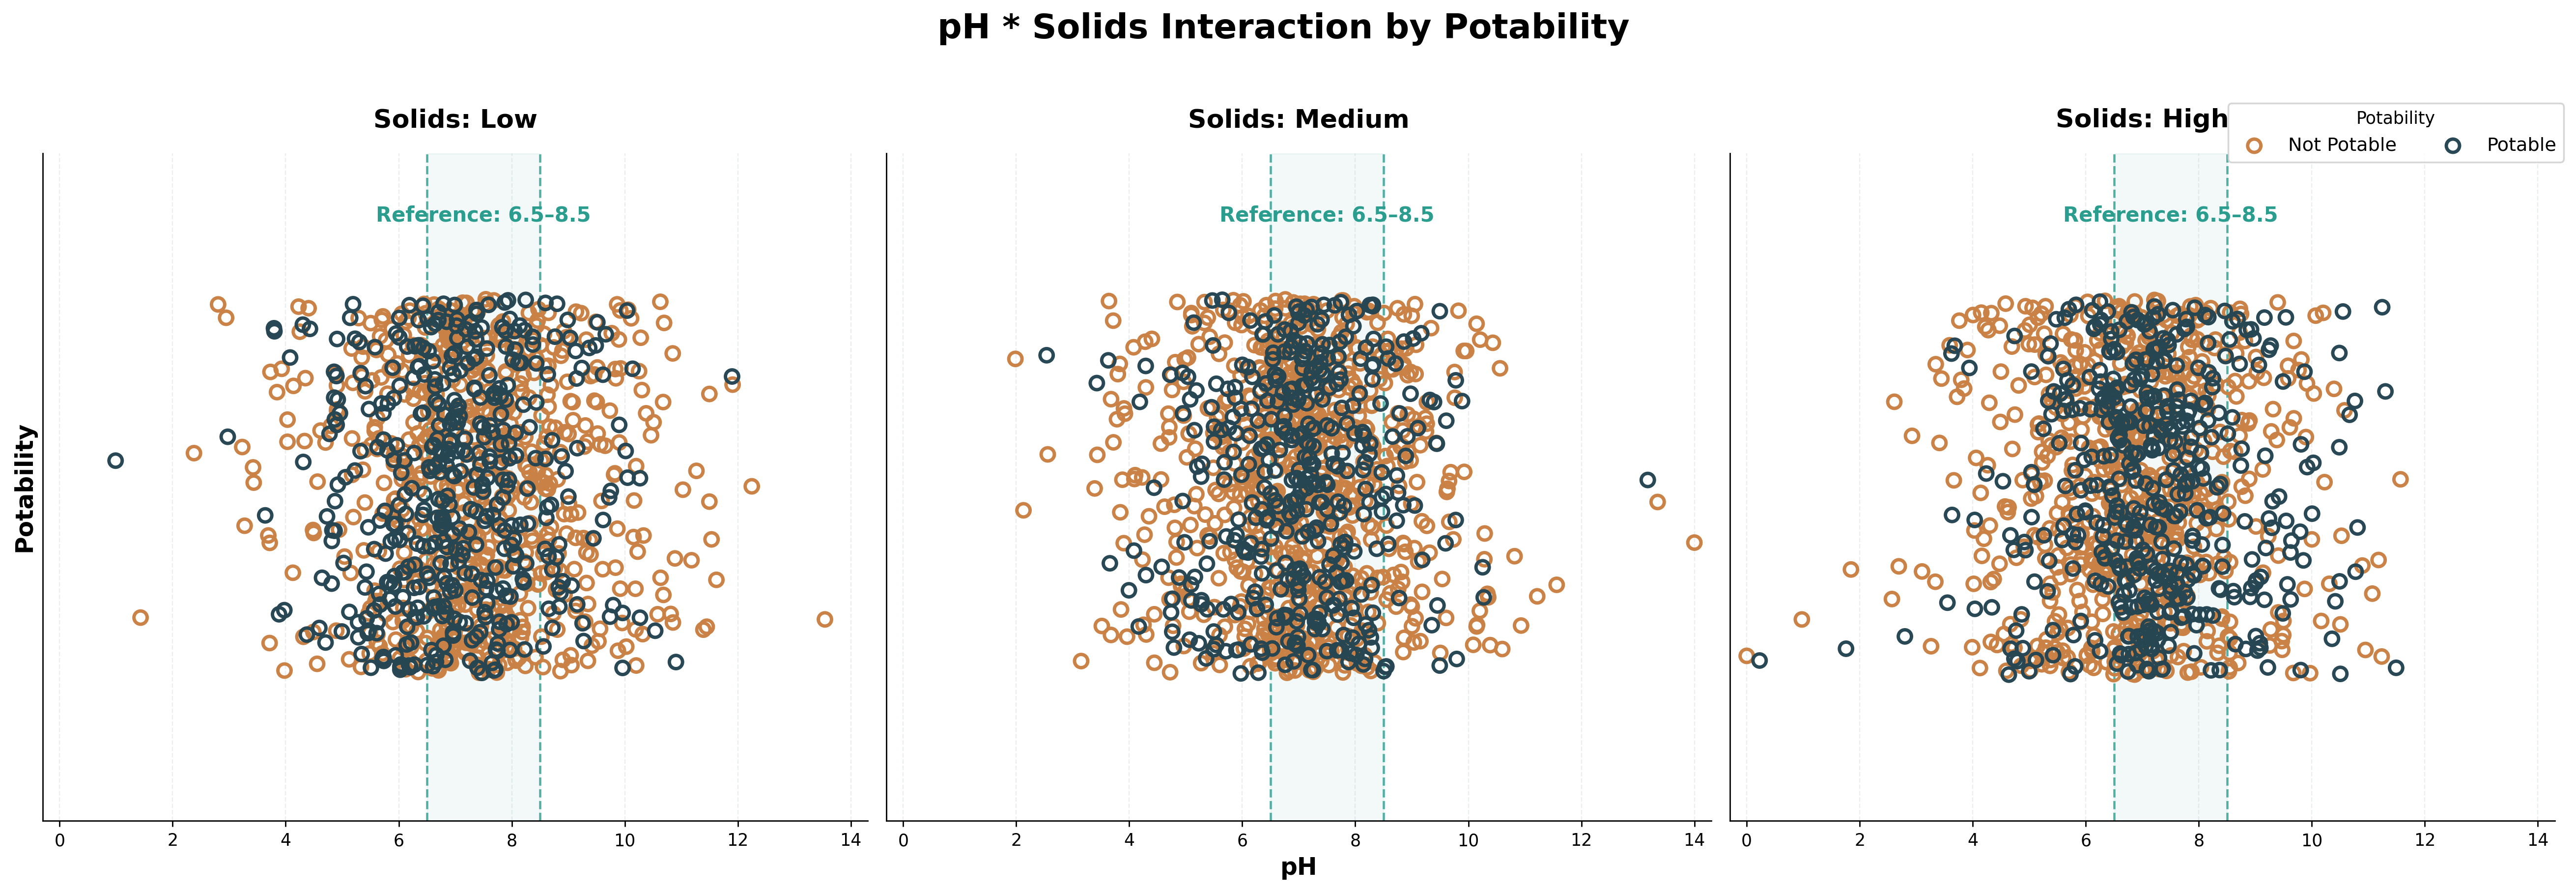

In [44]:
df = Data3_Clean_After_KNN.copy()

# Divide Solids into 3 levels
df["Solids_Level"] = pd.qcut(
    df["Solids"],
    q=3,
    labels=["Low", "Medium", "High"]
)

# COLORS

COLOR_NOT_POTABLE = "#CA8145"
COLOR_POTABLE = "#264653"

COLOR_NORMAL = "#2A9D8F"
COLOR_BORDERLINE = "#E9C46A"
COLOR_OUTSIDE = "#E76F51"

TEXT_COLOR = "#000000"
GRID_COLOR = "#B0BEC5"

fig, axes = plt.subplots(
    1,
    3,
    figsize=(21, 7),
    dpi=250,
    sharex=True,
    sharey=True
)


levels = ["Low", "Medium", "High"]

# COMMON LIMITS

x_min = df["ph"].min() - 0.3
x_max = df["ph"].max() + 0.3

y_min = -0.08
y_max = 0.08

# PLOT

np.random.seed(42)

for ax, level in zip(axes, levels):

    subset = df[
        df["Solids_Level"] == level
    ]

    not_potable = subset[
        subset["Potability"] == 0
    ]

    potable = subset[
        subset["Potability"] == 1
    ]

    # pH REFERENCE RANGE

    ax.axvspan(
        6.5,
        8.5,
        color=COLOR_NORMAL,
        alpha=0.06,
        zorder=0
    )

    ax.axvline(
        6.5,
        color=COLOR_NORMAL,
        linestyle="--",
        linewidth=1.3,
        alpha=0.8,
        zorder=1
    )

    ax.axvline(
        8.5,
        color=COLOR_NORMAL,
        linestyle="--",
        linewidth=1.3,
        alpha=0.8,
        zorder=1
    )

    # JITTER

    y_not_potable = np.random.uniform(
        -0.045,
        0.045,
        len(not_potable)
    )

    y_potable = np.random.uniform(
        -0.045,
        0.045,
        len(potable)
    )

    # NOT POTABLE

    ax.scatter(
        not_potable["ph"],
        y_not_potable,
        s=60,
        facecolors="none",
        edgecolors=COLOR_NOT_POTABLE,
        linewidths=2,
        alpha=0.99,
        marker="o",
        label="Not Potable",
        zorder=3
    )

    # POTABLE

    ax.scatter(
        potable["ph"],
        y_potable,
        s=60,
        facecolors="none",
        edgecolors=COLOR_POTABLE,
        linewidths=2,
        alpha=0.99,
        marker="o",
        label="Potable",
        zorder=3
    )

    # pH RANGE LABEL

    ax.text(
        7.5,
        0.065,
        "Reference: 6.5–8.5",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        color=COLOR_NORMAL
    )

    # PANEL TITLE

    ax.set_title(
        f"Solids: {level}",
        fontsize=15,
        fontweight="bold",
        color=TEXT_COLOR,
        pad=15
    )

    # GRID

    ax.grid(
        linestyle="--",
        linewidth=0.7,
        color=GRID_COLOR,
        alpha=0.25
    )

    # SPINES

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # LIMITS

    ax.set_xlim(
        x_min,
        x_max
    )

    ax.set_ylim(
        y_min,
        y_max
    )

# AXIS LABELS

axes[0].set_ylabel(
    "Potability",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_xlabel(
    "pH",
    fontsize=14,
    fontweight="bold"
)

axes[0].set_yticks([])

# MAIN TITLE

fig.suptitle(
    "pH * Solids Interaction by Potability",
    fontsize=20,
    fontweight="bold",
    color=TEXT_COLOR,
    y=1.03
)

# LEGEND

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Potability",
    loc="right",
    bbox_to_anchor=(1, 0.89),
    ncol=5,
    frameon=True,
    fontsize=11,

)

plt.tight_layout()
plt.show()

> ##### Neither pH alone nor the simple combination of pH × Solids creates a clear analogy between Potable and Not Potable.
> ##### Changing the Solids level did not create a new pattern either.We have a lot of overlap in all three areas, meaning that as Solids increase, we do not see a clear change in pH behavior relative to Potability.
> ##### A significant portion of the samples fall within the Reference range, but within this range both Potable and Not Potable classes are present. So, pH being within the Reference range does not alone determine Potability. Most of the data is within the standard range.
> ##### pH shows very weak marginal association with Potability, and the conditional analysis across Low/Medium/High Solids levels does not reveal a clear interaction or separation between potable and non-potable samples.

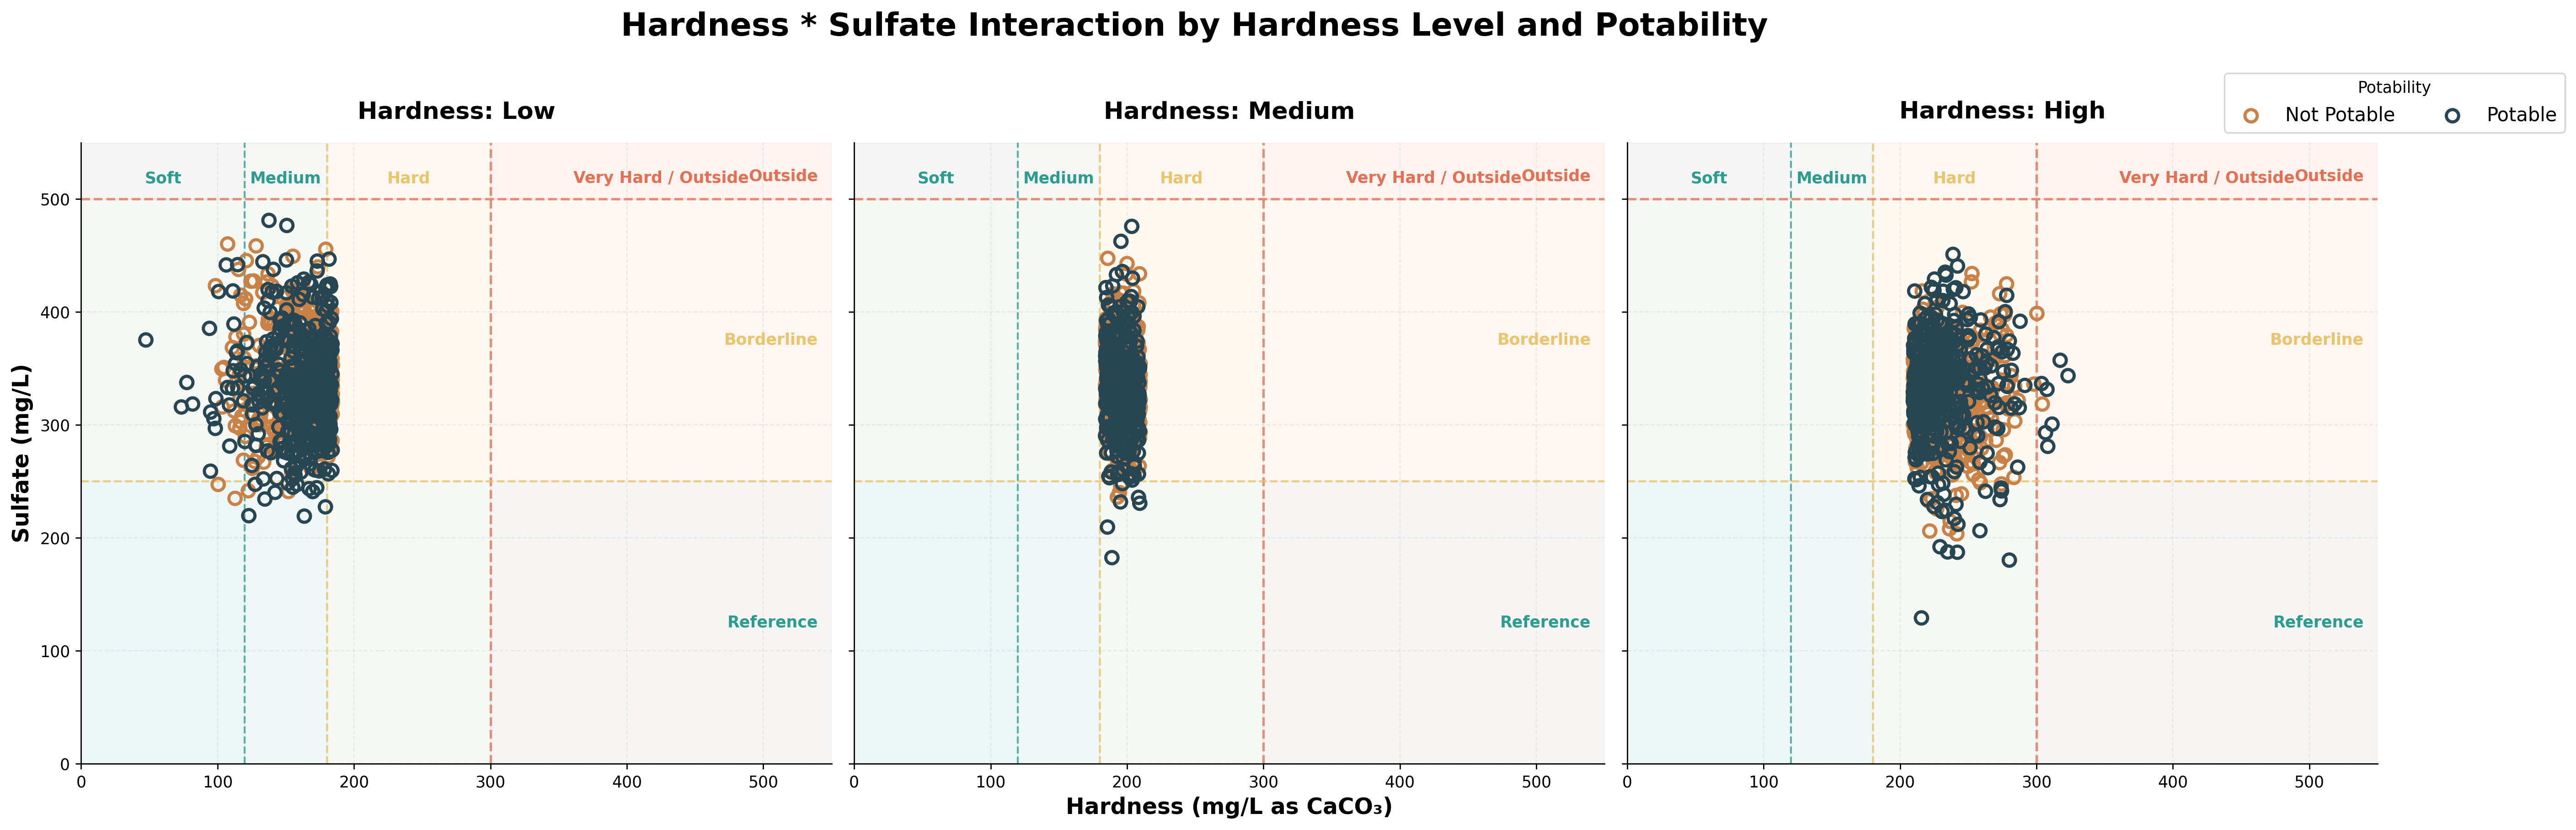

In [45]:
df = Data3_Clean_After_KNN.copy()

# Divide Hardness into 3 levels
df["Hardness_Level"] = pd.qcut(
    df["Hardness"],
    q=3,
    labels=["Low", "Medium", "High"]
)

# COLORS

COLOR_NOT_POTABLE = "#CA8145"
COLOR_POTABLE = "#264653"

COLOR_NORMAL = "#2A9D8F"
COLOR_BORDERLINE = "#E9C46A"
COLOR_OUTSIDE = "#E76F51"

TEXT_COLOR = "#000000"
GRID_COLOR = "#B0BEC5"

fig, axes = plt.subplots(
    1,
    3,
    figsize=(21, 7),
    dpi=250,
    sharex=True,
    sharey=True
)


levels = ["Low", "Medium", "High"]

# COMMON AXIS LIMITS

x_min = 0
x_max = max(
    550,
    df["Hardness"].max() + 20
)

y_min = 0
y_max = max(
    550,
    df["Sulfate"].max() + 20
)

# PLOT

for ax, level in zip(axes, levels):

    subset = df[
        df["Hardness_Level"] == level
    ]

    not_potable = subset[
        subset["Potability"] == 0
    ]

    potable = subset[
        subset["Potability"] == 1
    ]

    # HARDNESS BACKGROUND

    # Soft / Reference
    ax.axvspan(
        0,
        120,
        color=COLOR_NORMAL,
        alpha=0.045,
        zorder=0
    )

    # Medium / Reference
    ax.axvspan(
        120,
        180,
        color=COLOR_NORMAL,
        alpha=0.035,
        zorder=0
    )

    # Hard / Borderline
    ax.axvspan(
        180,
        300,
        color=COLOR_BORDERLINE,
        alpha=0.045,
        zorder=0
    )

    # Very Hard / Outside
    ax.axvspan(
        300,
        x_max,
        color=COLOR_OUTSIDE,
        alpha=0.035,
        zorder=0
    )

    # SULFATE BACKGROUND

    # Reference
    ax.axhspan(
        0,
        250,
        color=COLOR_NORMAL,
        alpha=0.035,
        zorder=0
    )

    # Borderline
    ax.axhspan(
        250,
        500,
        color=COLOR_BORDERLINE,
        alpha=0.045,
        zorder=0
    )

    # Outside
    ax.axhspan(
        500,
        y_max,
        color=COLOR_OUTSIDE,
        alpha=0.035,
        zorder=0
    )

    # HARDNESS REFERENCE LINES

    ax.axvline(
        120,
        color=COLOR_NORMAL,
        linestyle="--",
        linewidth=1.2,
        alpha=0.75,
        zorder=1
    )

    ax.axvline(
        180,
        color=COLOR_BORDERLINE,
        linestyle="--",
        linewidth=1.3,
        alpha=0.8,
        zorder=1
    )

    ax.axvline(
        300,
        color=COLOR_OUTSIDE,
        linestyle="--",
        linewidth=1.5,
        alpha=0.8,
        zorder=1
    )

    # SULFATE REFERENCE LINES

    ax.axhline(
        250,
        color=COLOR_BORDERLINE,
        linestyle="--",
        linewidth=1.3,
        alpha=0.8,
        zorder=1
    )

    ax.axhline(
        500,
        color=COLOR_OUTSIDE,
        linestyle="--",
        linewidth=1.5,
        alpha=0.8,
        zorder=1
    )

    # HARDNESS RANGE LABELS

    ax.text(
        60,
        y_max - 25,
        "Soft",
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold",
        color=COLOR_NORMAL,
        zorder=5
    )

    ax.text(
        150,
        y_max - 25,
        "Medium",
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold",
        color=COLOR_NORMAL,
        zorder=5
    )

    ax.text(
        240,
        y_max - 25,
        "Hard",
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold",
        color=COLOR_BORDERLINE,
        zorder=5
    )

    ax.text(
        (300 + x_max) / 2,
        y_max - 25,
        "Very Hard / Outside",
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold",
        color=COLOR_OUTSIDE,
        zorder=5
    )

    # SULFATE RANGE LABELS

    ax.text(
        x_max - 10,
        125,
        "Reference",
        ha="right",
        va="center",
        fontsize=10,
        fontweight="bold",
        color=COLOR_NORMAL,
        zorder=5
    )

    ax.text(
        x_max - 10,
        375,
        "Borderline",
        ha="right",
        va="center",
        fontsize=10,
        fontweight="bold",
        color=COLOR_BORDERLINE,
        zorder=5
    )

    ax.text(
        x_max - 10,
        520,
        "Outside",
        ha="right",
        va="center",
        fontsize=10,
        fontweight="bold",
        color=COLOR_OUTSIDE,
        zorder=5
    )

    # NOT POTABLE

    ax.scatter(
        not_potable["Hardness"],
        not_potable["Sulfate"],
        s=60,
        facecolors="none",
        edgecolors=COLOR_NOT_POTABLE,
        linewidths=2,
        alpha=1,
        marker="o",
        label="Not Potable",
        zorder=3
    )

    # POTABLE

    ax.scatter(
        potable["Hardness"],
        potable["Sulfate"],
        s=60,
        facecolors="none",
        edgecolors=COLOR_POTABLE,
        linewidths=2,
        alpha=1,
        marker="o",
        label="Potable",
        zorder=3
    )

    # PANEL TITLE

    ax.set_title(
        f"Hardness: {level}",
        fontsize=15,
        fontweight="bold",
        color=TEXT_COLOR,
        pad=15
    )

    # GRID

    ax.grid(
        linestyle="--",
        linewidth=0.7,
        color=GRID_COLOR,
        alpha=0.25,
        zorder=1
    )

    # SPINES

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # LIMITS

    ax.set_xlim(
        x_min,
        x_max
    )

    ax.set_ylim(
        y_min,
        y_max
    )

# AXIS LABELS

axes[0].set_ylabel(
    "Sulfate (mg/L)",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_xlabel(
    "Hardness (mg/L as CaCO₃)",
    fontsize=14,
    fontweight="bold"
)

# MAIN TITLE

fig.suptitle(
    "Hardness * Sulfate Interaction by Hardness Level and Potability",
    fontsize=20,
    fontweight="bold",
    color=TEXT_COLOR,
    y=1.03
)

# LEGEND

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Potability",
    loc="upper center",
    bbox_to_anchor=(1, 0.965),
    ncol=2,
    frameon=True,
    fontsize=12
)

plt.tight_layout()
plt.show()

> ##### At all three hardness levels, most samples are concentrated in Sulfate around 250–400 mg/L.
> ##### There is no clear difference between Potable and Not Potable.
> ##### As Hardness increases, the distribution of points shifts slightly.
> ##### The Hardness × Sulfate interaction does not reveal a strong visual separation between potable and non-potable water samples. Although the distributions of Sulfate vary across Hardness levels, substantial overlap between the two Potability classes remains evident. Therefore, this interaction does not appear to be a strong candidate for explaining Potability in this dataset.

# ✅Summary

| Feature             | Pearson | Spearman |         MI | Distribution / EDA                     | Interaction Signal                               | Final Verdict           |
| ------------------- | ------: | -------: | ---------: | -------------------------------------- | ------------------------------------------------ | ----------------------- |
| **Solids**          | +0.0343 |  +0.0264 |     0.0001 | Right-skewed، , has high values        |In combination with pH, showed an interesting pattern            | 🟡 **Potential**        |
| **Organic_carbon**  | −0.0318 |  −0.0287 |     0.0025 | Relatively continuous distribution     |In the previous interaction, it did not produce a clear separation      | 🔴 **Weak**             |
| **Chloramines**     | +0.0238 |  +0.0251 |     0.0000 | Relatively compact distribution        |Solids did not produce a clear separation.           | 🔴 **Weak**             |
| **Sulfate**         | −0.0196 |  −0.0118 |     0.0167 | Considerable dispersion                |Very high overlap with Hardness                  | 🟡 **Potential / Weak** |
| **Hardness**        | −0.0128 |  −0.0095 | **0.0270** | Relatively widespread distribution     | Hardness × Sulfate did not have a clear separation.           | 🟡 **Potential**        |
| **Conductivity**    | −0.0082 |  −0.0105 |     0.0068 | Relatively high dispersion             |Reviewed in combination with Turbidity                  | 🟡 **Potential**        |
| **Trihalomethanes** | +0.0075 |  +0.0055 |     0.0000 | Relatively high dispersion             |Used for stratification, separation was not strong | 🔴 **Weak**             |
| **pH**              | −0.0018 |  +0.0003 |     0.0000 | Wide range, from acidic to alkaline    | **pH × Solids** showed an interesting combination pattern     | 🟡 **Potential**        |
| **Turbidity**       | +0.0018 |  +0.0014 |     0.0035 | Mainly concentrated in the lower range |Turbidity checked with Conductivity                     | 🟡 **Potential / Weak** |


> ##### The exploratory analysis did not reveal a strong individual association between any water-quality feature and Potability. Pearson, Spearman, and Mutual Information analyses consistently indicated weak marginal relationships. Interaction analyses also showed substantial overlap between potable and non-potable samples, suggesting that Potability is likely influenced by complex multivariate and potentially nonlinear relationships rather than by a single dominant feature.